# Assignment 4 - Edge Computing & Intelligent Systems
## Knowledge Distillation (Q1) + Hardware-Aware Neural Architecture Search (Q2)

**What you will build in this single notebook**

| Part | What happens | Assignment requirement |
|---|---|---|
| **Part 0** | Setup, theme, data helpers | - |
| **Part 1** | Train a **ResNet-50 teacher** on CIFAR-100 | Q1 - req. 1 |
| **Part 2** | Build **MobileNetV2, SqueezeNet, EfficientNet-Lite0** students | Q1 - req. 2 |
| **Part 3** | **Baseline** students (no distillation) | Q1 - req. 5 |
| **Part 4** | **Knowledge distillation** (soft targets + temperature + hard labels + feature distillation) | Q1 - req. 3, 4 |
| **Part 5** | Unified inference pipeline + ONNX export + ONNX Runtime CPU inference | Q1 - req. 6, 7 |
| **Part 6** | **Hardware-aware NAS** with Optuna on CIFAR-10 | Q2 - req. 1-8 |
| **Part 7** | Benchmark everything, save CSVs, README, ZIP | Deliverables 9-13 |

### How to run (local laptop version, RTX 4050)
1. Run `setup_windows.bat` (or `bash setup_linux.sh`) **once**. It creates a private Python environment in the `.venv` folder inside this project.
2. Start Jupyter with `run_jupyter.bat` (or `bash run_jupyter.sh`) and open this notebook.
3. Run all cells from top to bottom. Plug in the charger and use the *High performance* power mode (a laptop GPU slows down when throttled).
4. **If the notebook stops or you close it, just run all cells again.** Finished models are loaded instead of retrained, a model that was mid-training continues from its last finished epoch, and the NAS search continues from its last finished trial.
5. **Everything lives inside this folder** (environment, datasets, caches, models, results). To remove it all from your disk, delete the folder.
6. `QUICK_TEST = True` writes to a separate folder (`EdgeAI_Assignment4_QUICK`) so a smoke test never mixes with the real run. To redo something from scratch, set `FORCE_RETRAIN = True`.

## Part 0 - Setup
The libraries (`timm` for EfficientNet-Lite0, `onnx` + `onnxruntime` for deployment, `optuna` for NAS) were installed into `.venv` by the setup script. This cell only checks that they are all there.

In [1]:
import importlib.util
missing = [m for m in ("torch", "torchvision", "timm", "onnx", "onnxruntime", "optuna", "pandas", "matplotlib", "psutil")
           if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError(f"Missing libraries: {missing}. Run setup_windows.bat (or setup_linux.sh) first and start Jupyter with run_jupyter.bat / run_jupyter.sh.")
print("All required libraries are installed.")

All required libraries are installed.


### 0.1 Imports and configuration
Everything you may want to change is in this one cell.

* `QUICK_TEST` - tiny run to check that everything works (1 epoch, small data).
* `FORCE_RETRAIN` - set `True` to ignore saved checkpoints and retrain.

In [2]:
import os
from pathlib import Path

# Keep every cache INSIDE the project folder so that deleting the folder removes everything.
_P = Path.cwd().resolve()
os.environ["TORCH_HOME"]     = str(_P / ".cache" / "torch")          # pretrained ResNet-50 weights
os.environ["MPLCONFIGDIR"]   = str(_P / ".cache" / "matplotlib")
os.environ["XDG_CACHE_HOME"] = str(_P / ".cache")
os.environ["HF_HOME"]        = str(_P / ".cache" / "huggingface")
(_P / ".cache" / "matplotlib").mkdir(parents=True, exist_ok=True)

import sys, time, json, copy, math, random, subprocess, zipfile, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import timm
import optuna
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ------------------------- USER SETTINGS -------------------------
QUICK_TEST    = os.environ.get("EDGEAI_QUICK", "0") == "1"   # True = tiny smoke test (~10 min), False = full experiment
FORCE_RETRAIN = False   # True = ignore saved checkpoints
SEED          = 42
# -----------------------------------------------------------------

if QUICK_TEST:
    TEACHER_EPOCHS, STUDENT_EPOCHS = 1, 1
    N_TRIALS, NAS_EPOCHS, NAS_TRAIN_N, FINAL_NAS_EPOCHS = 4, 1, 2000, 2
    ORT_EVAL_N, SUBSET = 500, 5000
else:
    TEACHER_EPOCHS, STUDENT_EPOCHS = 15, 20
    N_TRIALS, NAS_EPOCHS, NAS_TRAIN_N, FINAL_NAS_EPOCHS = 30, 4, 15000, 30
    ORT_EVAL_N, SUBSET = 2000, None

# ---------------- folders ----------------
PROJECT_DIR = Path.cwd().resolve()          # = the folder that contains this notebook
RUN_NAME = "EdgeAI_Assignment4_QUICK" if QUICK_TEST else "EdgeAI_Assignment4"
ROOT     = PROJECT_DIR / RUN_NAME            # checkpoints, ONNX, results, figures
DATA_DIR = PROJECT_DIR / "data"              # CIFAR datasets (downloaded only once)
if PROJECT_DIR not in Path(sys.prefix).resolve().parents:
    print("NOTE: this Python environment is not inside the project folder. Use run_jupyter.bat / run_jupyter.sh "
          "if you want everything to live in one deletable folder.")
CKPT, ONNX_DIR, RES_DIR, FIG_DIR = ROOT / "checkpoints", ROOT / "onnx", ROOT / "results", ROOT / "figures"
for p in (DATA_DIR, CKPT, ONNX_DIR, RES_DIR, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision only on GPU
torch.backends.cudnn.benchmark = True
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if USE_AMP else 0.0
TEACHER_BS = 64 if VRAM_GB < 9 else 128      # ResNet-50 teacher needs a smaller batch on a 6 GB laptop GPU

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

print("Device       :", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU only (will be slow)")
print("Torch / timm :", torch.__version__, "/", timm.__version__)
print("Output folder:", ROOT)
print("Dataset cache:", DATA_DIR)
if USE_AMP:
    print(f"GPU memory   : {VRAM_GB:.1f} GB -> teacher batch size {TEACHER_BS}")
else:
    print("WARNING: no CUDA GPU found. Check the NVIDIA driver and that setup installed the CUDA build of PyTorch. A full run on CPU is impractical; use QUICK_TEST = True.")
run_config = dict(seed=SEED, quick_test=QUICK_TEST, teacher_epochs=TEACHER_EPOCHS,
                  student_epochs=STUDENT_EPOCHS, nas_trials=N_TRIALS,
                  nas_candidate_epochs=NAS_EPOCHS, nas_train_samples=NAS_TRAIN_N,
                  nas_final_epochs=FINAL_NAS_EPOCHS, ort_eval_samples=ORT_EVAL_N,
                  teacher_batch_size=TEACHER_BS, torch_version=torch.__version__,
                  cuda_available=USE_AMP, gpu=torch.cuda.get_device_name(0) if USE_AMP else None)
(RES_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")


C:\Edge_assignment_4\EdgeAI_Local\EdgeAI_Local\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device       : cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Torch / timm : 2.6.0+cu126 / 1.0.15
Output folder: C:\Edge_assignment_4\EdgeAI_Local\EdgeAI_Local\EdgeAI_Assignment4
Dataset cache: C:\Edge_assignment_4\EdgeAI_Local\EdgeAI_Local\data
GPU memory   : 6.4 GB -> teacher batch size 64


355

### 0.1b What is already saved? (resume status)
This cell lists what is already saved in the project folder, so you can see what will be **loaded** and what still has to be **trained**.
Models trained earlier (for example on Colab) can be reused: copy their `.pt` files into `checkpoints/` inside the folder shown above.

In [3]:
def status():
    names = ["teacher_resnet50"] + [f"{s}_{v}" for s in ["mobilenet_v2", "squeezenet", "efficientnet_lite0"] for v in ("baseline", "kd")] + ["nas_best"]
    rows = []
    for n in names:
        rows.append(dict(model=n, finished=(CKPT / f"{n}.pt").exists(), partial_progress=(CKPT / f"{n}_resume.pt").exists()))
    rows.append(dict(model="CIFAR-100 dataset cached", finished=(DATA_DIR / "cifar-100-python").exists(), partial_progress=False))
    rows.append(dict(model="CIFAR-10 dataset cached", finished=(DATA_DIR / "cifar-10-batches-py").exists(), partial_progress=False))
    rows.append(dict(model="NAS search history", finished=(RES_DIR / "nas_search_history.json").exists(), partial_progress=False))
    display(pd.DataFrame(rows))
status()

,model,finished,partial_progress
0,teacher_resnet50,False,False
1,mobilenet_v2_baseline,False,False
2,mobilenet_v2_kd,False,False
3,squeezenet_baseline,False,False
4,squeezenet_kd,False,False
5,efficientnet_lite0_baseline,False,False
6,efficientnet_lite0_kd,False,False
7,nas_best,False,False
8,CIFAR-100 dataset cached,True,False
9,CIFAR-10 dataset cached,True,False


### 0.2 Visual theme
All plots in this notebook use your colour palette:
`#282E2E #303028 #877257 #AFA07F #574034 #A17F62 #EAD5BE #E56800 #A60000`.

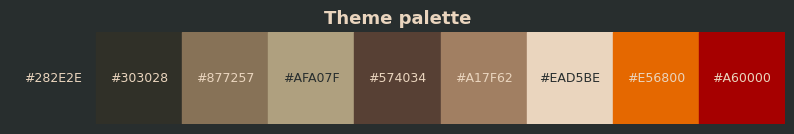

In [4]:
C = dict(bg="#282E2E", panel="#303028", brown="#877257", sand="#AFA07F", dark="#574034",
         tan="#A17F62", cream="#EAD5BE", orange="#E56800", red="#A60000")
CYCLE = [C["orange"], C["sand"], C["tan"], C["brown"], C["red"], C["cream"]]
CMAP  = LinearSegmentedColormap.from_list("theme", [C["panel"], C["dark"], C["brown"], C["orange"], C["cream"]])

plt.rcParams.update({
    "figure.facecolor": C["bg"], "savefig.facecolor": C["bg"], "axes.facecolor": C["panel"],
    "axes.edgecolor": C["brown"], "axes.labelcolor": C["cream"], "axes.titlecolor": C["cream"],
    "axes.titleweight": "bold", "axes.titlesize": 13, "text.color": C["cream"],
    "xtick.color": C["sand"], "ytick.color": C["sand"], "grid.color": C["dark"],
    "axes.grid": True, "grid.alpha": 0.6, "axes.prop_cycle": cycler(color=CYCLE),
    "legend.facecolor": C["panel"], "legend.edgecolor": C["brown"], "legend.labelcolor": C["cream"],
    "font.size": 11, "figure.dpi": 100,
})

def show(name):
    """Save the current figure into figures/ and display it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()

# quick preview of the palette
fig, ax = plt.subplots(figsize=(10, 1.2))
for i, (k, v) in enumerate(C.items()):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=v))
    ax.text(i + 0.5, 0.5, v, ha="center", va="center", fontsize=9,
            color="#EAD5BE" if k not in ("cream", "sand") else "#282E2E")
ax.set_xlim(0, len(C)); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title("Theme palette")
plt.show()

### 0.3 Fast data pipeline (whole dataset lives on the GPU)
CIFAR images are tiny (32x32), so we keep the **entire dataset on the GPU as uint8** and do normalisation, random-crop and flip augmentation on the GPU too. This removes the slow Colab `DataLoader` bottleneck and makes training much faster.

In [5]:
def load_cifar(name):
    """Download CIFAR-10/100 and return everything as GPU tensors."""
    cls = torchvision.datasets.CIFAR100 if name == "cifar100" else torchvision.datasets.CIFAR10
    tr = cls(root=str(DATA_DIR), train=True,  download=True)
    te = cls(root=str(DATA_DIR), train=False, download=True)
    def conv(ds):
        x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()     # uint8 (N,3,32,32)
        y = torch.tensor(ds.targets, dtype=torch.long)
        return x, y
    xtr, ytr = conv(tr); xte, yte = conv(te)
    if SUBSET:                                   # only used by QUICK_TEST
        xtr, ytr, xte, yte = xtr[:SUBSET], ytr[:SUBSET], xte[:SUBSET // 5], yte[:SUBSET // 5]
    f = xtr.float().div(255)
    mean, std = f.mean((0, 2, 3)), f.std((0, 2, 3))
    del f
    return dict(name=name, xtr=xtr.to(DEVICE), ytr=ytr.to(DEVICE), xte=xte.to(DEVICE), yte=yte.to(DEVICE),
                mean=mean.to(DEVICE), std=std.to(DEVICE), classes=list(tr.classes), num_classes=len(tr.classes))

def preprocess(x_u8, mean, std, res=None):
    """uint8 (B,3,H,W) -> normalised float, optionally resized to res x res. Works on CPU or GPU."""
    x = x_u8.float().div(255)
    if res is not None and x.shape[-1] != res:
        x = F.interpolate(x, size=(res, res), mode="bilinear", align_corners=False)
    return ((x - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)).contiguous()

def augment(x):
    """Random crop (zero padding) + random horizontal flip, per-sample, on GPU."""
    B, Cc, H, W = x.shape
    pad = max(2, H // 8)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    iy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ix = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = iy[:, None] + torch.arange(H, device=x.device)[None, :]
    cols = ix[:, None] + torch.arange(W, device=x.device)[None, :]
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(Cc, device=x.device)[None, :, None, None]
    return xp[b, c, rows[:, None, :, None], cols[:, None, None, :]]

def batches(x, y, bs, shuffle, mean, std, res=None, aug=False):
    n = x.shape[0]
    idx = torch.randperm(n, device=x.device) if shuffle else torch.arange(n, device=x.device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        if shuffle and j.numel() < bs:           # drop last partial batch while training
            continue
        xb = preprocess(x[j], mean, std, res)
        if aug:
            xb = augment(xb)
        yield xb, y[j]

@torch.no_grad()
def evaluate(model, x, y, mean, std, res=None, bs=64):
    model.eval()
    correct = 0
    for xb, yb in batches(x, y, bs, False, mean, std, res):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        correct += (out.argmax(1) == yb).sum().item()
    return correct / len(y)

D100 = load_cifar("cifar100")
print(f"CIFAR-100 -> train {tuple(D100['xtr'].shape)}, test {tuple(D100['xte'].shape)}, classes {D100['num_classes']}")

CIFAR-100 -> train (50000, 3, 32, 32), test (10000, 3, 32, 32), classes 100


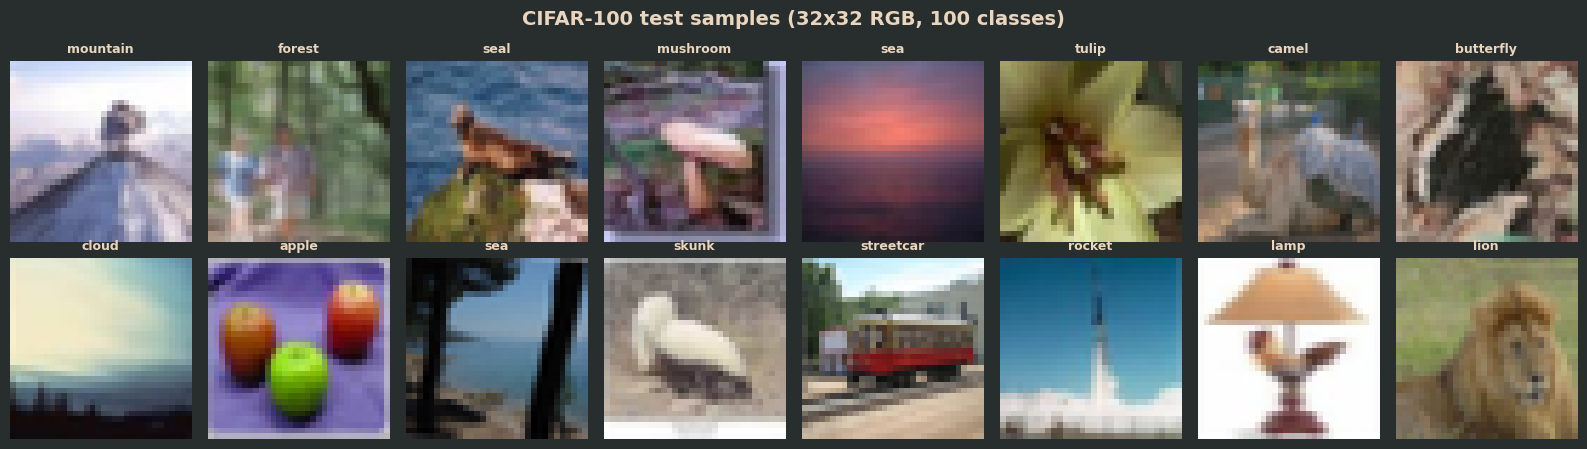

In [6]:
# Visualise a few CIFAR-100 images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(D100["xte"][i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(D100["classes"][D100["yte"][i].item()], fontsize=9)
    ax.axis("off")
fig.suptitle("CIFAR-100 test samples (32x32 RGB, 100 classes)", color=C["cream"], fontsize=14, fontweight="bold")
show("00_cifar100_samples")

### 0.4 Generic training engine (used by teacher, students, baselines, KD *and* NAS)
One function `train_model` does all training:

* **Baseline mode** (`teacher=None`): plain cross-entropy with hard labels.
* **Distillation mode** (`teacher` and `kd` given): the loss is

$$\mathcal{L} = \alpha \, T^2 \, KL\big(\mathrm{softmax}(z_t/T)\,\|\,\mathrm{softmax}(z_s/T)\big) + (1-\alpha)\, CE(z_s, y) + \beta\,\mathcal{L}_{feat}$$

  * **Soft targets + temperature `T`**: the teacher's softened probabilities tell the student *how classes relate* ("dark knowledge").
  * **Hard labels**: the normal cross-entropy with the true labels, mixed in with weight `1-alpha`.
  * **Feature distillation** (FitNets-style): a small 1x1-conv *regressor* maps the student's intermediate feature map to the teacher's feature map, and we minimise `1 - cosine similarity`. The regressor is thrown away after training, so the student stays lightweight.

In [7]:
HIST_FILE = RES_DIR / "histories.json"
HIST = json.load(open(HIST_FILE)) if HIST_FILE.exists() else {}
def save_hist():
    tmp = HIST_FILE.with_suffix(".json.tmp")
    tmp.write_text(json.dumps(HIST), encoding="utf-8")
    os.replace(tmp, HIST_FILE)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def atomic_save(obj, path):
    """Write to a temp file first, then rename - a disconnect can never leave a half-written checkpoint."""
    tmp = Path(str(path) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

class FeatureHook:
    """Stores the output of a chosen layer during the forward pass."""
    def __init__(self, module):
        self.out = None
        self.handle = module.register_forward_hook(self._fn)
    def _fn(self, module, inp, out):
        self.out = out
    def remove(self):
        self.handle.remove()

def feature_module(name, m):
    """The intermediate layer of each student used for feature distillation (last feature map)."""
    if name == "efficientnet_lite0":
        return m.bn2                  # timm: BatchNorm+activation after the 1x1 head conv
    return m.features                 # torchvision MobileNetV2 / SqueezeNet

def kd_terms(s_logits, t_logits, y, T):
    """Return (soft-target KL loss scaled by T^2, hard-label CE)."""
    s, t = s_logits.float(), t_logits.float()
    soft = F.kl_div(F.log_softmax(s / T, dim=1), F.softmax(t / T, dim=1), reduction="batchmean") * (T * T)
    hard = F.cross_entropy(s, y)
    return soft, hard

def feature_loss(s_feat, t_feat, reg):
    t = F.adaptive_avg_pool2d(t_feat, s_feat.shape[-2:]).float()   # match spatial size
    s = reg(s_feat).float()                                        # match channels
    return (1.0 - F.cosine_similarity(s, t, dim=1)).mean()

def train_model(model, tag, data, epochs, opt_name="adamw", lr=2e-3, wd=5e-2, bs=128,
                teacher=None, kd=None, student_key=None, res=None, save_path=None, verbose=True):
    model.to(DEVICE)
    use_feat = bool(teacher is not None and kd is not None and kd.get("use_feat"))
    s_hook = t_hook = reg = None
    params = list(model.parameters())
    if use_feat:
        t_hook = FeatureHook(teacher.layer4)
        s_hook = FeatureHook(feature_module(student_key, model))
        model.eval(); teacher.eval()
        with torch.no_grad():                                      # find feature shapes
            dummy = torch.zeros(2, 3, 32, 32, device=DEVICE)
            teacher(dummy); model(dummy)
        sc, tc = s_hook.out.shape[1], t_hook.out.shape[1]
        reg = nn.Sequential(nn.Conv2d(sc, tc, 1, bias=False), nn.BatchNorm2d(tc)).to(DEVICE)
        params += list(reg.parameters())

    if opt_name == "sgd":
        opt = torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    else:
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    steps = max(1, data["xtr"].shape[0] // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs, steps_per_epoch=steps, pct_start=0.2)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    # ---- resume support: progress is saved after every epoch ----
    hist = dict(epoch=[], train_loss=[], val_acc=[], time=[])
    start_ep = 1
    resume_path = CKPT / f"{tag}_resume.pt"
    best_path = CKPT / f"{tag}_best.pt"
    best_acc = -1.0
    if resume_path is not None and resume_path.exists() and not FORCE_RETRAIN:
        try:
            st = torch.load(resume_path, map_location=DEVICE, weights_only=False)
            model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"])
            sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
            if reg is not None and st.get("reg") is not None:
                reg.load_state_dict(st["reg"])
            hist, start_ep = st["hist"], st["epoch"] + 1
            best_acc = st.get("best_acc", max(hist["val_acc"], default=-1.0))
            if "rng" in st:
                random.setstate(st["rng"]["python"])
                np.random.set_state(st["rng"]["numpy"])
                torch.set_rng_state(st["rng"]["torch"].cpu())
                if USE_AMP: torch.cuda.set_rng_state_all([s.cpu() for s in st["rng"]["cuda"]])
            print(f"[{tag}] resuming after epoch {st['epoch']}/{epochs}")
        except Exception as e:
            raise RuntimeError(f"Cannot safely resume {tag} from {resume_path}; preserve the snapshot and inspect the error.") from e

    for ep in range(start_ep, epochs + 1):
        model.train()
        if reg is not None: reg.train()
        if teacher is not None: teacher.eval()
        t0, tot, nb = time.time(), torch.zeros((), device=DEVICE), 0
        for xb, yb in batches(data["xtr"], data["ytr"], bs, True, data["mean"], data["std"], res, aug=True):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
                if teacher is None:
                    loss = F.cross_entropy(out.float(), yb)                       # baseline
                else:
                    with torch.no_grad():
                        t_out = teacher(xb)
                    soft, hard = kd_terms(out, t_out, yb, kd["T"])
                    loss = kd["alpha"] * soft + (1.0 - kd["alpha"]) * hard        # soft + hard
                    if use_feat:
                        loss = loss + kd["beta"] * feature_loss(s_hook.out, t_hook.out, reg)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(params, 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.detach(); nb += 1
        acc = evaluate(model, data["xte"], data["yte"], data["mean"], data["std"], res)
        hist["epoch"].append(ep); hist["train_loss"].append(float(tot.item() / max(nb, 1)))
        hist["val_acc"].append(acc); hist["time"].append(time.time() - t0)
        if not math.isfinite(hist["train_loss"][-1]):
            raise FloatingPointError(f"Non-finite training loss for {tag}; previous checkpoint preserved.")
        if verbose:
            print(f"[{tag}] epoch {ep:>2}/{epochs}  loss {hist['train_loss'][-1]:.3f}  acc {acc*100:5.2f}%  ({hist['time'][-1]:.0f}s)")
        HIST[tag] = hist
        save_hist()
        if acc > best_acc:
            best_acc = acc
            atomic_save(model.state_dict(), best_path)
        if resume_path is not None:
            atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                             scaler=scaler.state_dict(), reg=(reg.state_dict() if reg is not None else None),
                             hist=hist, epoch=ep, best_acc=best_acc,
                             rng=dict(python=random.getstate(), numpy=np.random.get_state(),
                                      torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if USE_AMP else [])), resume_path)
            epoch_dir = CKPT / "epochs" / tag
            epoch_dir.mkdir(parents=True, exist_ok=True)
            epoch_path = epoch_dir / f"epoch_{ep:03d}.pt"
            if epoch_path.exists():
                epoch_path = epoch_dir / f"epoch_{ep:03d}_{time.time_ns()}.pt"
            try:
                os.link(resume_path, epoch_path)
            except OSError:
                import shutil
                shutil.copy2(resume_path, epoch_path)


    if s_hook is not None: s_hook.remove()
    if t_hook is not None: t_hook.remove()
    model.eval()
    if save_path is not None:
        atomic_save(model.state_dict(), save_path)
    return hist

def run_or_load(make_fn, tag, data, epochs, **kw):
    """Train a model, or reload it if a checkpoint already exists (handy after an interruption)."""
    set_seed(SEED)                                   # identical init for baseline and KD students
    model = make_fn()
    path = CKPT / f"{tag}.pt"
    if path.exists() and not FORCE_RETRAIN:
        model.load_state_dict(torch.load(path, map_location="cpu"))
        model.to(DEVICE).eval()
        if tag not in HIST:                                  # checkpoint exists but its history file is missing
            a = evaluate(model, data["xte"], data["yte"], data["mean"], data["std"], kw.get("res"))
            HIST[tag] = dict(epoch=[epochs], train_loss=[float("nan")], val_acc=[a], time=[0.0])
            save_hist()
        print(f"[{tag}] loaded existing checkpoint - NOT retrained (test acc {HIST[tag]['val_acc'][-1]*100:.2f}%)")
        return model
    HIST[tag] = train_model(model, tag, data, epochs, save_path=path, **kw)
    save_hist()
    # Preserve the final optimizer/RNG/feature-adapter snapshot.
    # (CKPT / f"{tag}_resume.pt").unlink(missing_ok=True)     # finished: the partial-progress file is no longer needed
    if USE_AMP: torch.cuda.empty_cache()
    return model

## Part 1 - Teacher: ResNet-50 on CIFAR-100  *(Deliverable 1)*
We use torchvision's ResNet-50, initialised from ImageNet weights (so it converges quickly) and adapted to 32x32 images:
the stride of the first conv is 1 and the first max-pool is removed, so small images are not shrunk too early. The last layer becomes a 100-way classifier.

In [8]:
def make_teacher(num_classes=100, pretrained=True):
    try:
        w = torchvision.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        m = torchvision.models.resnet50(weights=w)
    except Exception as e:
        raise RuntimeError("ImageNet teacher initialization failed; check the local weight cache or network.") from e
    m.conv1.stride = (1, 1)           # keep resolution for 32x32 inputs
    m.maxpool = nn.Identity()
    m.fc = nn.Linear(2048, num_classes)
    return m

teacher = run_or_load(make_teacher, "teacher_resnet50", D100, TEACHER_EPOCHS, opt_name="sgd", lr=0.05 * TEACHER_BS / 128, wd=5e-4, bs=TEACHER_BS)
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)
t_acc = evaluate(teacher, D100["xte"], D100["yte"], D100["mean"], D100["std"])
print(f"\nTeacher ResNet-50 | params {count_params(teacher)/1e6:.1f}M | CIFAR-100 test accuracy {t_acc*100:.2f}%")

[teacher_resnet50] epoch  1/15  loss 2.180  acc 73.18%  (67s)


[teacher_resnet50] epoch  2/15  loss 0.838  acc 76.06%  (63s)


[teacher_resnet50] epoch  3/15  loss 0.701  acc 77.79%  (63s)


[teacher_resnet50] epoch  4/15  loss 0.591  acc 77.19%  (63s)


[teacher_resnet50] epoch  5/15  loss 0.507  acc 78.04%  (64s)


[teacher_resnet50] epoch  6/15  loss 0.446  acc 78.33%  (63s)


... (6 outputs left out)

[teacher_resnet50] epoch 13/15  loss 0.062  acc 84.59%  (63s)


[teacher_resnet50] epoch 14/15  loss 0.034  acc 85.13%  (63s)


[teacher_resnet50] epoch 15/15  loss 0.027  acc 85.23%  (63s)



Teacher ResNet-50 | params 23.7M | CIFAR-100 test accuracy 85.23%


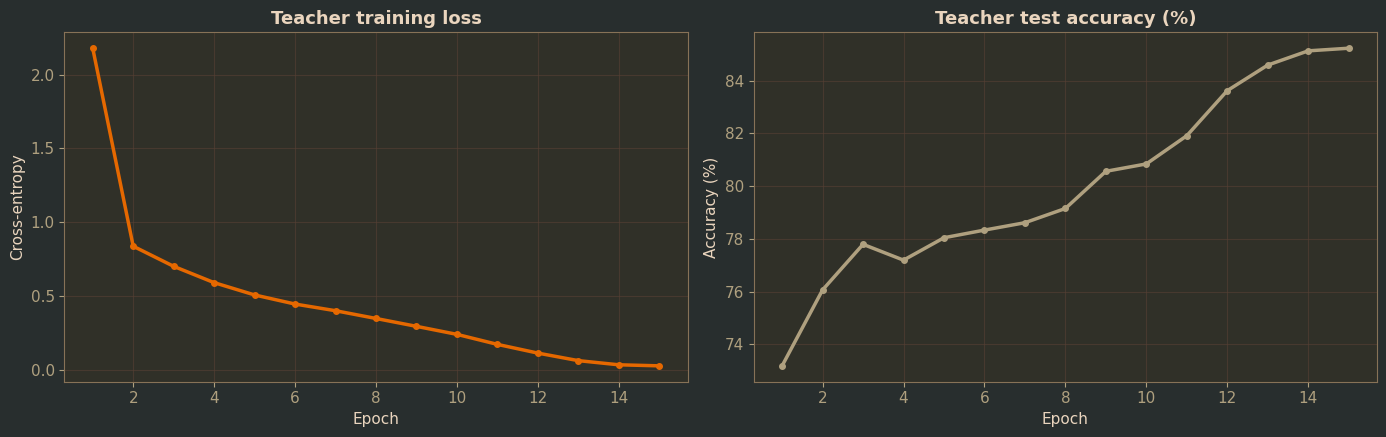

In [9]:
h = HIST["teacher_resnet50"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(h["epoch"], h["train_loss"], color=C["orange"], lw=2.5, marker="o", ms=4)
ax[0].set_title("Teacher training loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy")
ax[1].plot(h["epoch"], [a * 100 for a in h["val_acc"]], color=C["sand"], lw=2.5, marker="o", ms=4)
ax[1].set_title("Teacher test accuracy (%)"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)")
show("01_teacher_training")

### What does the teacher know? (soft targets & temperature)
A hard label says only "this is a *bus*". The teacher's softened output also says "it looks a bit like a *streetcar* and a *pickup truck*".
Raising the temperature `T` flattens the distribution so the student can see these hints. This plot shows the teacher's top-8 probabilities for one test image at three temperatures.

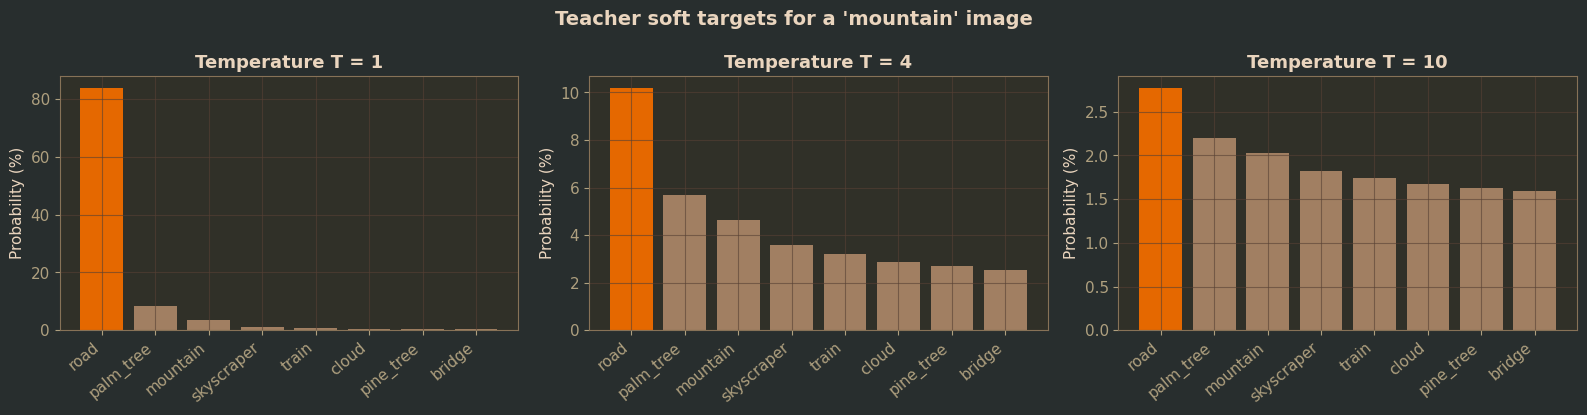

In [10]:
teacher.eval()
with torch.no_grad():
    lg = teacher(preprocess(D100["xte"][:1], D100["mean"], D100["std"])).float().cpu()[0]
true_name = D100["classes"][D100["yte"][0].item()]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, T in zip(axes, (1, 4, 10)):
    p = F.softmax(lg / T, dim=0)
    top = p.topk(8)
    ax.bar(range(8), top.values.numpy() * 100, color=[C["orange"] if i == 0 else C["tan"] for i in range(8)])
    ax.set_xticks(range(8)); ax.set_xticklabels([D100["classes"][i] for i in top.indices], rotation=40, ha="right")
    ax.set_title(f"Temperature T = {T}"); ax.set_ylabel("Probability (%)")
fig.suptitle(f"Teacher soft targets for a '{true_name}' image", color=C["cream"], fontsize=14, fontweight="bold")
show("02_temperature_effect")

## Part 2 - Student architectures  *(Deliverable 2)*
Three lightweight students, all adapted to 32x32 CIFAR images (smaller strides so the feature maps do not vanish):

| Student | Key idea | Source |
|---|---|---|
| **MobileNetV2** | inverted residuals + depthwise-separable convs | torchvision |
| **SqueezeNet 1.1** | *Fire modules* (squeeze 1x1 -> expand 1x1 + 3x3) | torchvision |
| **EfficientNet-Lite0** | MBConv blocks, ReLU6, no SE (edge-friendly EfficientNet) | `timm` |

,student,params_M,fp32_size_MB,output_shape
0,MobileNetV2,2.35,9.41,"(2, 100)"
1,SqueezeNet,0.77,3.10,"(2, 100)"
2,EfficientNet-Lite0,3.50,14.00,"(2, 100)"
3,ResNet-50 (teacher),23.71,94.85,"(2, 100)"


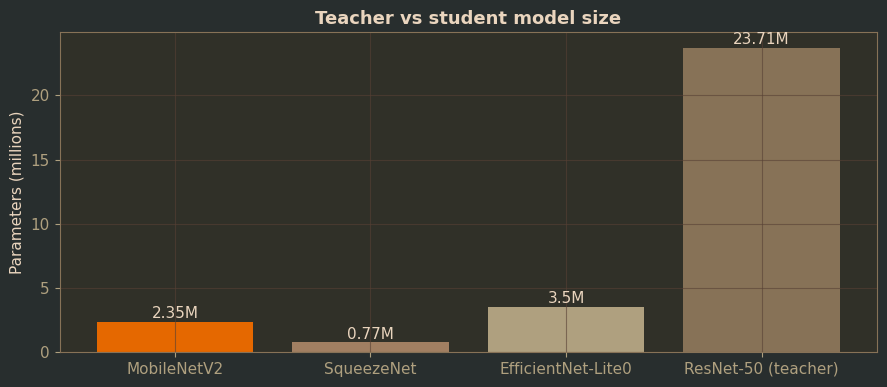

In [11]:
STUDENTS = ["mobilenet_v2", "squeezenet", "efficientnet_lite0"]
PRETTY   = {"mobilenet_v2": "MobileNetV2", "squeezenet": "SqueezeNet", "efficientnet_lite0": "EfficientNet-Lite0"}
LR       = {"mobilenet_v2": 2e-3, "squeezenet": 1e-3, "efficientnet_lite0": 2e-3}   # SqueezeNet has no BatchNorm -> smaller LR

def make_student(name, num_classes=100):
    if name == "mobilenet_v2":
        m = torchvision.models.mobilenet_v2(weights=None, num_classes=num_classes)
        m.features[0][0].stride = (1, 1)                       # stem stride 2 -> 1
    elif name == "squeezenet":
        m = torchvision.models.squeezenet1_1(weights=None, num_classes=num_classes)
        m.features[0].stride = (1, 1); m.features[0].padding = (1, 1)
        m.features[2] = nn.Identity()                          # drop the first max-pool
        m.classifier[2] = nn.Identity()                        # remove final ReLU so outputs are real logits
    elif name == "efficientnet_lite0":
        m = timm.create_model("efficientnet_lite0", pretrained=False, num_classes=num_classes)
        m.conv_stem.stride = (1, 1)
    else:
        raise ValueError(name)
    return m

rows = []
for s in STUDENTS:
    m = make_student(s)
    with torch.no_grad():
        out = m.eval()(torch.zeros(2, 3, 32, 32))
    rows.append(dict(student=PRETTY[s], params_M=round(count_params(m) / 1e6, 2),
                     fp32_size_MB=round(count_params(m) * 4 / 1e6, 2), output_shape=tuple(out.shape)))
rows.append(dict(student="ResNet-50 (teacher)", params_M=round(count_params(teacher) / 1e6, 2),
                 fp32_size_MB=round(count_params(teacher) * 4 / 1e6, 2), output_shape=(2, 100)))
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(9, 4))
names = [r["student"] for r in rows]; vals = [r["params_M"] for r in rows]
bars = ax.bar(names, vals, color=[C["orange"], C["tan"], C["sand"], C["brown"]])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v}M", ha="center", color=C["cream"])
ax.set_ylabel("Parameters (millions)"); ax.set_title("Teacher vs student model size")
show("03_model_sizes")

## Part 3 - Baseline students (no distillation)  *(Deliverable 3)*
This is the **separate baseline pipeline**: each student is trained only with hard labels (cross-entropy).
It is our control - any improvement of the distilled students must be measured against these numbers.
Baseline and distilled students start from **exactly the same random initialisation** (same seed) so the comparison is fair.

In [12]:
def train_baseline(s):
    """Baseline pipeline: student trained with hard labels only."""
    return run_or_load(lambda: make_student(s), f"{s}_baseline", D100, STUDENT_EPOCHS, lr=LR[s])

baseline_models = {}
for s in STUDENTS:
    baseline_models[s] = train_baseline(s)

[mobilenet_v2_baseline] epoch  1/20  loss 4.418  acc  5.87%  (29s)


[mobilenet_v2_baseline] epoch  2/20  loss 3.964  acc 11.59%  (26s)


[mobilenet_v2_baseline] epoch  3/20  loss 3.566  acc 16.88%  (26s)


[mobilenet_v2_baseline] epoch  4/20  loss 3.237  acc 20.65%  (26s)


[mobilenet_v2_baseline] epoch  5/20  loss 2.955  acc 26.50%  (27s)


[mobilenet_v2_baseline] epoch  6/20  loss 2.729  acc 31.59%  (26s)


... (50 outputs left out)

[efficientnet_lite0_baseline] epoch 17/20  loss 1.413  acc 53.84%  (25s)


[efficientnet_lite0_baseline] epoch 18/20  loss 1.348  acc 54.08%  (25s)


[efficientnet_lite0_baseline] epoch 19/20  loss 1.306  acc 54.52%  (25s)


[efficientnet_lite0_baseline] epoch 20/20  loss 1.288  acc 54.58%  (25s)


## Part 4 - Knowledge distillation  *(Deliverable 4)*
Hyper-parameters:

* `T = 4` - temperature for the softmax,
* `alpha = 0.7` - 70 % soft-target loss, 30 % hard-label loss,
* `beta = 1.0` - weight of the feature-distillation loss (teacher `layer4` -> student last feature map).

In [13]:
KD_CFG = dict(T=4.0, alpha=0.7, beta=1.0, use_feat=True)

def train_distilled(s):
    """KD pipeline: soft targets + temperature + hard labels + feature distillation."""
    return run_or_load(lambda: make_student(s), f"{s}_kd", D100, STUDENT_EPOCHS, lr=LR[s],
                       teacher=teacher, kd=KD_CFG, student_key=s)

kd_models = {}
for s in STUDENTS:
    kd_models[s] = train_distilled(s)

[mobilenet_v2_kd] epoch  1/20  loss 12.449  acc  5.65%  (42s)


[mobilenet_v2_kd] epoch  2/20  loss 11.203  acc 10.41%  (40s)


[mobilenet_v2_kd] epoch  3/20  loss 10.368  acc 16.55%  (40s)


[mobilenet_v2_kd] epoch  4/20  loss 9.474  acc 21.13%  (40s)


[mobilenet_v2_kd] epoch  5/20  loss 8.662  acc 25.97%  (41s)


[mobilenet_v2_kd] epoch  6/20  loss 7.983  acc 32.53%  (42s)


... (50 outputs left out)

[efficientnet_lite0_kd] epoch 17/20  loss 4.203  acc 56.61%  (43s)


[efficientnet_lite0_kd] epoch 18/20  loss 4.045  acc 57.18%  (43s)


[efficientnet_lite0_kd] epoch 19/20  loss 3.973  acc 57.49%  (43s)


[efficientnet_lite0_kd] epoch 20/20  loss 3.929  acc 57.47%  (43s)


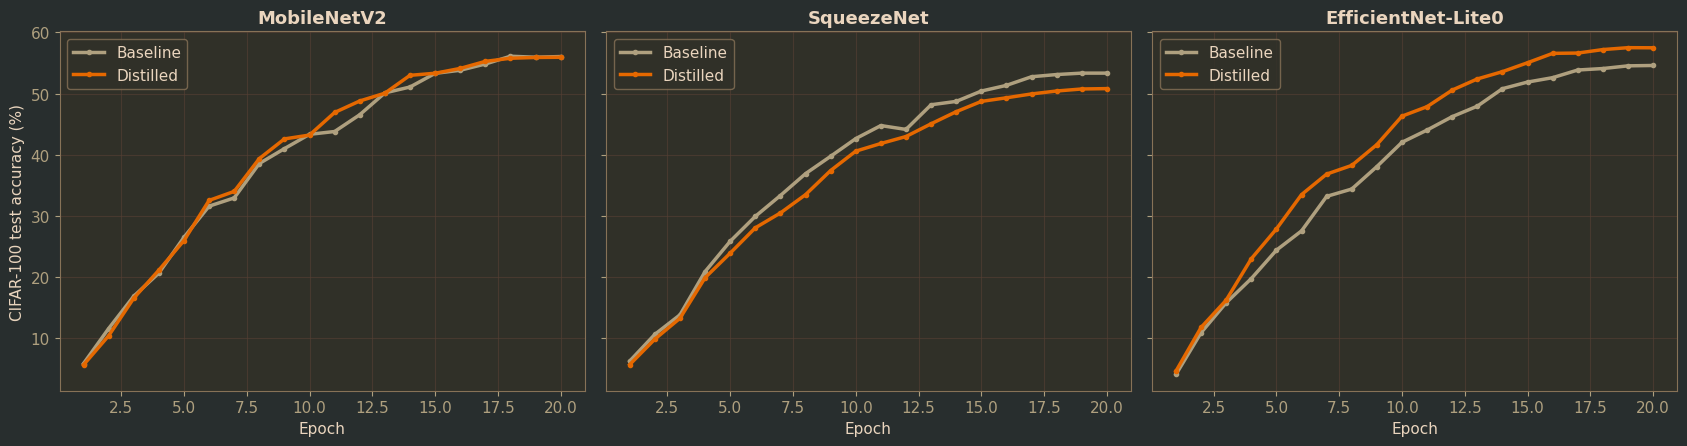

,student,baseline_acc,distilled_acc,kd_gain
0,MobileNetV2,56.04,55.92,-0.12
1,SqueezeNet,53.33,50.80,-2.53
2,EfficientNet-Lite0,54.58,57.47,2.89


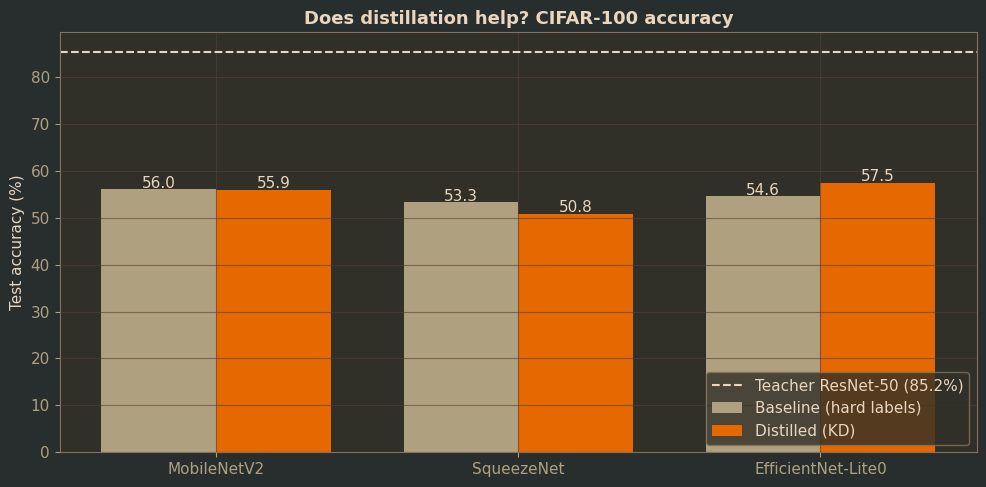

In [14]:
# ---- Learning curves: baseline vs distilled ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, s in zip(axes, STUDENTS):
    for variant, col, lab in (("baseline", C["sand"], "Baseline"), ("kd", C["orange"], "Distilled")):
        h = HIST[f"{s}_{variant}"]
        ax.plot(h["epoch"], [a * 100 for a in h["val_acc"]], color=col, lw=2.5, marker="o", ms=3, label=lab)
    ax.set_title(PRETTY[s]); ax.set_xlabel("Epoch"); ax.legend()
axes[0].set_ylabel("CIFAR-100 test accuracy (%)")
show("04_baseline_vs_kd_curves")

# ---- Final accuracy comparison ----
res_rows = []
for s in STUDENTS:
    b = evaluate(baseline_models[s], D100["xte"], D100["yte"], D100["mean"], D100["std"])
    k = evaluate(kd_models[s],       D100["xte"], D100["yte"], D100["mean"], D100["std"])
    res_rows.append(dict(student=PRETTY[s], baseline_acc=b * 100, distilled_acc=k * 100, kd_gain=(k - b) * 100))
kd_df = pd.DataFrame(res_rows)
kd_df.to_csv(RES_DIR / "kd_vs_baseline.csv", index=False)
display(kd_df.round(2))

x = np.arange(len(kd_df)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w / 2, kd_df["baseline_acc"],  w, color=C["sand"],   label="Baseline (hard labels)")
b2 = ax.bar(x + w / 2, kd_df["distilled_acc"], w, color=C["orange"], label="Distilled (KD)")
ax.axhline(t_acc * 100, color=C["cream"], ls="--", lw=1.5, label=f"Teacher ResNet-50 ({t_acc*100:.1f}%)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.3, f"{r.get_height():.1f}", ha="center", color=C["cream"])
ax.set_xticks(x); ax.set_xticklabels(kd_df["student"]); ax.set_ylabel("Test accuracy (%)")
ax.set_title("Does distillation help? CIFAR-100 accuracy"); ax.legend(loc="lower right")
show("05_kd_accuracy_comparison")

> **Reading the result:** a positive `kd_gain` means the student learned something extra from the teacher.
> If a gain is small or negative for a student, report it honestly in your write-up and explain why (short training budget, tiny student capacity, or the SqueezeNet/EfficientNet feature maps being a poor match for the teacher's features). Honest analysis scores better than hiding it.

## Part 5 - Unified inference, ONNX export & ONNX Runtime CPU inference  *(Deliverables 9, 10)*

### 5.1 ONNX export + CPU measurement helpers
* `export_onnx` converts a PyTorch model to a portable **ONNX** file (dynamic batch size).
* `make_session` creates an **ONNX Runtime CPU** session limited to **1 thread** - a fair stand-in for a small edge CPU.
* `measure_latency` = median time of a single-image forward pass (after warm-up).
* `measure_peak_mem` = extra RAM used while loading + running the model, measured in a **separate process** (Linux `ru_maxrss`), so it is not polluted by this notebook's memory.

In [15]:
def export_onnx(model, path, res=32, check=True):
    model = copy.deepcopy(model).cpu().eval()
    dummy = torch.randn(1, 3, res, res)
    kw = dict(input_names=["input"], output_names=["logits"],
              dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
    try:
        torch.onnx.export(model, dummy, str(path), dynamo=False, **kw)      # classic exporter (stable)
    except Exception:
        try:
            torch.onnx.export(model, dummy, str(path), **kw)                # older torch without `dynamo`
        except Exception:
            torch.onnx.export(model, dummy, str(path), input_names=["input"], output_names=["logits"], opset_version=17)
    if check:
        onnx.checker.check_model(onnx.load(str(path)))
    return path

def make_session(path):
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    return ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])

def ort_logits(sess, x_np, bs=100):
    """Run ONNX Runtime on a float32 numpy batch (handles fixed- or dynamic-batch models)."""
    inp = sess.get_inputs()[0]
    step = bs if not isinstance(inp.shape[0], int) else 1
    outs = [sess.run(None, {inp.name: x_np[i:i + step]})[0] for i in range(0, len(x_np), step)]
    return np.concatenate(outs, 0)

def measure_latency(sess, res, n_warm=20, n_runs=100):
    x = np.random.randn(1, 3, res, res).astype(np.float32)
    name = sess.get_inputs()[0].name
    for _ in range(n_warm):
        sess.run(None, {name: x})
    ts = []
    for _ in range(n_runs):
        t0 = time.perf_counter(); sess.run(None, {name: x}); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 95))

MEM_SCRIPT = """
import sys, os
import numpy as np
import onnxruntime as ort

def peak_mb():
    try:
        import resource                                   # Linux
        return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0
    except ImportError:
        import psutil                                     # Windows: peak working set
        return psutil.Process(os.getpid()).memory_info().peak_wset / 1048576.0

path, res = sys.argv[1], int(sys.argv[2])
base = peak_mb()
so = ort.SessionOptions(); so.intra_op_num_threads = 1
s = ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
x = np.random.randn(1, 3, res, res).astype(np.float32)
for _ in range(3):
    s.run(None, {s.get_inputs()[0].name: x})
print(max(peak_mb() - base, 0.0))
"""

def measure_peak_mem(path, res):
    """Peak extra RAM (MB) for ONNX Runtime inference. Returns NaN if unsupported on this OS."""
    try:
        out = subprocess.run([sys.executable, "-c", MEM_SCRIPT, str(path), str(res)],
                             capture_output=True, text=True, timeout=120)
        return float(out.stdout.strip().split()[-1])
    except Exception:
        return float("nan")

print("ONNX Runtime", ort.__version__, "| providers:", ort.get_available_providers())

ONNX Runtime 1.21.0 | providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


### 5.2 Registry of all trained models + unified predictor
`REG` stores everything needed to use a model (how to build it, its checkpoint, its ONNX file, its class names, its input size).
`UnifiedPredictor` is the **single inference pipeline**: give it a model key and a backend (`"torch"` or `"onnx"`) and it returns top-k predictions - the same code works for all three students (baseline or distilled) and, later, the NAS model.

In [16]:
REG = {}
for s in STUDENTS:
    for variant in ("baseline", "kd"):
        key = f"{s}_{variant}"
        REG[key] = dict(builder=(lambda s=s: make_student(s)), ckpt=CKPT / f"{key}.pt", onnx=ONNX_DIR / f"{key}.onnx",
                        data=D100, classes=D100["classes"], mean=D100["mean"].cpu(), std=D100["std"].cpu(), res=32,
                        dataset="CIFAR-100", arch=PRETTY[s], variant="Distilled" if variant == "kd" else "Baseline")

class UnifiedPredictor:
    """One inference pipeline for every model (students + NAS) and both backends."""
    def __init__(self, key, backend="onnx"):
        self.key, self.backend, self.info = key, backend, REG[key]
        if backend == "torch":
            self.model = self.info["builder"]()
            self.model.load_state_dict(torch.load(self.info["ckpt"], map_location="cpu"))
            self.model.eval()
        else:
            self.sess = make_session(self.info["onnx"])

    @torch.no_grad()
    def logits(self, x_u8):                       # x_u8: uint8 tensor (N,3,32,32) on CPU
        x = preprocess(x_u8.cpu(), self.info["mean"], self.info["std"], self.info["res"])
        if self.backend == "torch":
            return np.concatenate([self.model(x[i:i+64]).numpy() for i in range(0, len(x), 64)])
        return ort_logits(self.sess, x.numpy().astype(np.float32))

    def predict(self, x_u8, topk=1):
        lg = self.logits(x_u8)
        p = np.exp(lg - lg.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
        idx = np.argsort(-p, axis=1)[:, :topk]
        return [[(self.info["classes"][j], float(p[i, j])) for j in idx[i]] for i in range(len(p))]

# ---- export every student to ONNX and check that ONNX == PyTorch ----
rows = []
for key, info in REG.items():
    m = info["builder"](); m.load_state_dict(torch.load(info["ckpt"], map_location="cpu")); m.eval()
    export_onnx(m, info["onnx"], info["res"])
    xr = torch.randn(4, 3, info["res"], info["res"])
    with torch.no_grad():
        ref = m(xr).numpy()
    got = ort_logits(make_session(info["onnx"]), xr.numpy())
    rows.append(dict(model=key, onnx_file=info["onnx"].name, size_MB=round(info["onnx"].stat().st_size / 1e6, 2),
                     max_abs_diff_vs_torch=float(np.abs(ref - got).max())))
pd.DataFrame(rows).to_csv(RES_DIR / "onnx_export_checks.csv", index=False)
display(pd.DataFrame(rows))

,model,onnx_file,size_MB,max_abs_diff_vs_torch
0,mobilenet_v2_baseline,mobilenet_v2_baseline.onnx,9.38,0.000007
1,mobilenet_v2_kd,mobilenet_v2_kd.onnx,9.38,0.000002
2,squeezenet_baseline,squeezenet_baseline.onnx,3.11,0.000015
3,squeezenet_kd,squeezenet_kd.onnx,3.11,0.000003
4,efficientnet_lite0_baseline,efficientnet_lite0_baseline.onnx,13.95,0.000007
5,efficientnet_lite0_kd,efficientnet_lite0_kd.onnx,13.95,0.000004


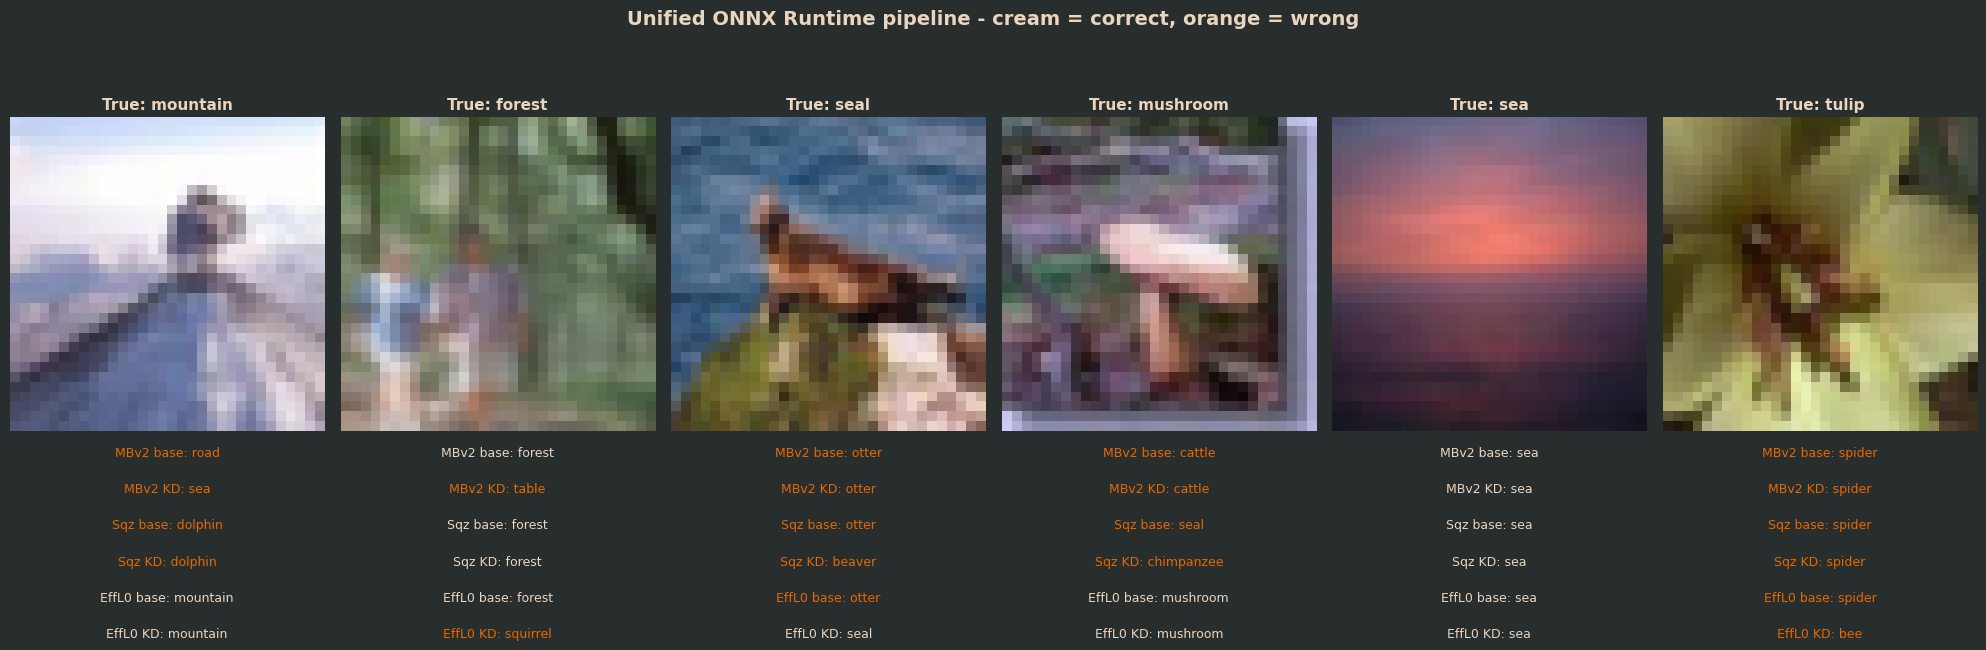

In [17]:
# ---- Same 6 test images through ALL student models with ONNX Runtime (CPU) ----
xs = D100["xte"][:6].cpu(); ys = D100["yte"][:6].cpu().numpy()
keys = list(REG.keys())
preds = {k: UnifiedPredictor(k, "onnx").predict(xs, topk=1) for k in keys}

fig, axes = plt.subplots(1, 6, figsize=(20, 5.6))
for i, ax in enumerate(axes):
    ax.imshow(xs[i].permute(1, 2, 0).numpy()); ax.axis("off")
    ax.set_title(f"True: {D100['classes'][ys[i]]}", fontsize=11)
    for r, k in enumerate(keys):
        name, prob = preds[k][i][0]
        ok = name == D100["classes"][ys[i]]
        short = k.replace("mobilenet_v2", "MBv2").replace("squeezenet", "Sqz").replace("efficientnet_lite0", "EffL0").replace("_baseline", " base").replace("_kd", " KD")
        ax.text(0.5, -0.08 - 0.115 * r, f"{short}: {name}", transform=ax.transAxes, ha="center", fontsize=9,
                color=C["cream"] if ok else C["orange"], clip_on=False)
fig.suptitle("Unified ONNX Runtime pipeline - cream = correct, orange = wrong", color=C["cream"], fontsize=14, fontweight="bold")
show("06_unified_inference_predictions")

## Part 6 - Hardware-aware Neural Architecture Search (CIFAR-10)  *(Question 2, Deliverables 5-8)*

**Goal:** automatically find a small CNN that is accurate *and* fits an edge-device budget.

### 6.1 Search space  *(Deliverable 5)*
| Dimension | Options |
|---|---|
| Input resolution | 16, 24, 32 |
| Convolutional depth (number of blocks) | 2 - 6 |
| Stem channels | 16, 24, 32 |
| Channels per block | 16, 24, 32, 48, 64, 96, 128 |
| Kernel size per block | 3, 5 |
| Block type | standard conv, **depthwise-separable** conv |
| Activation per block | ReLU, ReLU6, SiLU, Hardswish |
| Stride per block | 1 or 2 (at most 3 down-samplings) |

The **architecture generator** `build_model(cfg)` turns any sampled configuration (a Python dict) into a real PyTorch network.

In [18]:
SPACE = dict(resolution=[16, 24, 32], min_depth=2, max_depth=6, stem_channels=[16, 24, 32],
             channels=[16, 24, 32, 48, 64, 96, 128], kernels=[3, 5],
             block_types=["conv", "dwsep"], activations=["relu", "relu6", "silu", "hardswish"],
             strides=[1, 2], max_downsamples=3)

ACTS = {"relu": nn.ReLU, "relu6": nn.ReLU6, "silu": nn.SiLU, "hardswish": nn.Hardswish}

def conv_block(cin, cout, k, stride, act):
    """Standard conv -> BN -> activation."""
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout), ACTS[act]())

def dwsep_block(cin, cout, k, stride, act):
    """Depthwise conv -> BN -> act -> pointwise 1x1 conv -> BN -> act."""
    return nn.Sequential(
        nn.Conv2d(cin, cin, k, stride, k // 2, groups=cin, bias=False), nn.BatchNorm2d(cin), ACTS[act](),
        nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout), ACTS[act]())

class SearchedNet(nn.Module):
    """Network generated from an architecture configuration dict."""
    def __init__(self, cfg, num_classes=10):
        super().__init__()
        sc = cfg["stem_channels"]
        layers = [conv_block(3, sc, 3, 1, cfg["stem_act"])]
        c = sc
        for b in cfg["blocks"]:
            fn = dwsep_block if b["type"] == "dwsep" else conv_block
            layers.append(fn(c, b["out"], b["k"], b["stride"], b["act"]))
            c = b["out"]
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, num_classes))
    def forward(self, x):
        return self.head(self.features(x))

def build_model(cfg, num_classes=10):
    return SearchedNet(cfg, num_classes)

def sample_cfg(trial):
    """Turn an Optuna trial into an architecture config.
    Parameters for all 6 possible blocks are always suggested; only the first `depth` blocks are used."""
    res   = trial.suggest_categorical("resolution", SPACE["resolution"])
    depth = trial.suggest_int("depth", SPACE["min_depth"], SPACE["max_depth"])
    stem  = trial.suggest_categorical("stem_channels", SPACE["stem_channels"])
    stem_act = trial.suggest_categorical("stem_act", SPACE["activations"])
    blocks, downs = [], 0
    for i in range(SPACE["max_depth"]):
        t = trial.suggest_categorical(f"b{i}_type", SPACE["block_types"])
        ch = trial.suggest_categorical(f"b{i}_ch", SPACE["channels"])
        k = trial.suggest_categorical(f"b{i}_k", SPACE["kernels"])
        a = trial.suggest_categorical(f"b{i}_act", SPACE["activations"])
        s = trial.suggest_categorical(f"b{i}_stride", SPACE["strides"])
        if i < depth:
            if s == 2 and downs >= SPACE["max_downsamples"]:
                s = 1
            downs += int(s == 2)
            blocks.append(dict(type=t, out=ch, k=k, act=a, stride=s))
    return dict(resolution=res, stem_channels=stem, stem_act=stem_act, blocks=blocks)

# --- demo: build 3 random architectures and show their size ---
class _FakeTrial:
    def __init__(self, seed): self.r = random.Random(seed)
    def suggest_categorical(self, name, choices): return self.r.choice(choices)
    def suggest_int(self, name, lo, hi): return self.r.randint(lo, hi)

demo = []
for sd in range(3):
    cfg = sample_cfg(_FakeTrial(sd)); m = build_model(cfg)
    with torch.no_grad():
        o = m.eval()(torch.zeros(1, 3, cfg["resolution"], cfg["resolution"]))
    demo.append(dict(sample=sd, resolution=cfg["resolution"], depth=len(cfg["blocks"]),
                     types="/".join(b["type"] for b in cfg["blocks"]), params_K=round(count_params(m) / 1e3, 1), out_shape=tuple(o.shape)))
display(pd.DataFrame(demo))

,sample,resolution,depth,types,params_K,out_shape
0,0,24,5,dwsep/conv/conv/conv/conv,264.7,"(1, 10)"
1,1,16,6,conv/conv/dwsep/conv/conv/dwsep,89.4,"(1, 10)"
2,2,16,2,conv/conv,95.1,"(1, 10)"


### 6.2 Deployment constraints + search objective
Every candidate is first **converted to ONNX and measured on the CPU** (latency, file size, peak memory) *before* any training.
If it breaks a constraint it is **rejected immediately** (no training time wasted). Accepted candidates are trained briefly on a CIFAR-10 subset and scored:

`score = val_accuracy - 0.05 * (latency / max_latency) - 0.02 * (size / max_size)`

so that, among similar-accuracy networks, the faster and smaller one wins. Optuna's **TPE (Bayesian optimisation)** sampler proposes new candidates based on what worked in earlier trials.
You can change the limits in `CONSTRAINTS` to emulate a different device.

In [19]:
CONSTRAINTS = dict(max_latency_ms=10.0, max_size_mb=1.0, max_peak_mem_mb=200.0)

D10 = load_cifar("cifar10")
# Candidate evaluation split: NAS train subset and a held-out validation set, both from the TRAIN data
# (the CIFAR-10 test set is NOT used during the search, only for the final model).
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(D10["xtr"]), generator=g)
n_val = min(5000, len(perm) // 5)
val_idx = perm[:n_val].to(DEVICE)
tr_idx = perm[n_val:n_val + NAS_TRAIN_N].to(DEVICE)
NAS_DATA = dict(xtr=D10["xtr"][tr_idx], ytr=D10["ytr"][tr_idx], xte=D10["xtr"][val_idx], yte=D10["ytr"][val_idx],
                mean=D10["mean"], std=D10["std"])
print(f"CIFAR-10 | NAS train subset {len(tr_idx)} | NAS validation {len(val_idx)} | full train {len(D10['xtr'])} | test {len(D10['xte'])}")

def hardware_profile(model, res, tag):
    """Export to ONNX and measure REAL CPU latency, file size and peak memory."""
    path = ONNX_DIR / f"_tmp_{tag}.onnx"
    export_onnx(model, path, res, check=False)
    sess = make_session(path)
    lat, lat95 = measure_latency(sess, res, n_warm=10, n_runs=50)
    size = path.stat().st_size / 1e6
    mem = measure_peak_mem(path, res)
    del sess
    try:
        path.unlink()
    except OSError:
        pass
    return dict(latency_ms=lat, latency_p95_ms=lat95, size_mb=size, peak_mem_mb=mem)

def check_constraints(hw):
    bad = []
    if hw["latency_ms"] > CONSTRAINTS["max_latency_ms"]: bad.append("latency")
    if hw["size_mb"] > CONSTRAINTS["max_size_mb"]: bad.append("size")
    if not math.isnan(hw["peak_mem_mb"]) and hw["peak_mem_mb"] > CONSTRAINTS["max_peak_mem_mb"]: bad.append("memory")
    return bad

NAS_HIST_FILE = RES_DIR / "nas_search_history.json"
HISTORY = json.load(open(NAS_HIST_FILE)) if (NAS_HIST_FILE.exists() and not FORCE_RETRAIN) else []
def save_nas_history():
    tmp = NAS_HIST_FILE.with_suffix(".json.tmp")
    tmp.write_text(json.dumps(HISTORY), encoding="utf-8")
    os.replace(tmp, NAS_HIST_FILE)
print(f"Loaded {len(HISTORY)} previously evaluated NAS candidates" if HISTORY else "Starting a fresh NAS search")

def objective(trial):
    tid = len(HISTORY)                                        # continues numbering after a restart
    set_seed(SEED + tid)
    cfg = sample_cfg(trial)
    pending = dict(trial=tid, trial_params=dict(trial.params), config=cfg)
    pending_tmp = RES_DIR / "nas_pending.json.tmp"
    pending_tmp.write_text(json.dumps(pending, indent=2), encoding="utf-8")
    os.replace(pending_tmp, RES_DIR / "nas_pending.json")
    res = cfg["resolution"]
    model = build_model(cfg, 10)
    hw = hardware_profile(model, res, f"t{tid}")
    rec = dict(trial=tid, trial_params=dict(trial.params), resolution=res, depth=len(cfg["blocks"]), params=count_params(model), **hw,
               cfg_json=json.dumps(cfg))
    bad = check_constraints(hw)
    if bad:                                                   # hardware-aware rejection (before training)
        rec.update(status="rejected", reason="+".join(bad), val_acc=None, score=None)
        HISTORY.append(rec); save_nas_history()
        (RES_DIR / "nas_pending.json").unlink(missing_ok=True)
        print(f"trial {tid:>2} REJECTED ({rec['reason']}) lat {hw['latency_ms']:.1f}ms size {hw['size_mb']:.2f}MB")
        raise optuna.TrialPruned()
    h = train_model(model, f"nas_t{tid}", NAS_DATA, NAS_EPOCHS, lr=3e-3, res=res, verbose=False)
    acc = h["val_acc"][-1]
    atomic_save(model.state_dict(), CKPT / f"nas_t{tid}.pt")
    score = acc - 0.05 * hw["latency_ms"] / CONSTRAINTS["max_latency_ms"] - 0.02 * hw["size_mb"] / CONSTRAINTS["max_size_mb"]
    rec.update(status="accepted", reason="", val_acc=acc, score=score)
    HISTORY.append(rec); save_nas_history()
    (RES_DIR / "nas_pending.json").unlink(missing_ok=True)
    print(f"trial {tid:>2} ok  acc {acc*100:5.2f}%  lat {hw['latency_ms']:.1f}ms  size {hw['size_mb']:.2f}MB  "
          f"mem {hw['peak_mem_mb']:.0f}MB  score {score:.4f}")
    return score

CIFAR-10 | NAS train subset 15000 | NAS validation 5000 | full train 50000 | test 10000
Starting a fresh NAS search


### 6.3 Run the search  *(Deliverable 6)*
The first trial is a small hand-made architecture that is guaranteed to satisfy the constraints, so the search always has at least one valid candidate. The rest are proposed by Optuna.

In [20]:
def seed_params():
    p = {"resolution": 24, "depth": 3, "stem_channels": 16, "stem_act": "relu"}
    chs = [32, 48, 64, 64, 64, 64]
    for i in range(SPACE["max_depth"]):
        p.update({f"b{i}_type": "dwsep", f"b{i}_ch": chs[i], f"b{i}_k": 3, f"b{i}_act": "relu",
                  f"b{i}_stride": 2 if i < 2 else 1})
    return p

def param_distribution(name):
    Cat = optuna.distributions.CategoricalDistribution
    if name == "resolution":    return Cat(SPACE["resolution"])
    if name == "depth":         return optuna.distributions.IntDistribution(SPACE["min_depth"], SPACE["max_depth"])
    if name == "stem_channels": return Cat(SPACE["stem_channels"])
    if name == "stem_act":      return Cat(SPACE["activations"])
    key = name.split("_", 1)[1]                               # e.g. b3_ch -> ch
    return Cat({"type": SPACE["block_types"], "ch": SPACE["channels"], "k": SPACE["kernels"],
                "act": SPACE["activations"], "stride": SPACE["strides"]}[key])

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8))

# Re-teach the sampler what was learned before the disconnect (no re-training of old candidates)
for rec in HISTORY:
    prm = rec["trial_params"]
    dist = {k: param_distribution(k) for k in prm}
    if rec["status"] == "accepted":
        tr = optuna.trial.create_trial(params=prm, distributions=dist, value=rec["score"])
    else:
        tr = optuna.trial.create_trial(state=optuna.trial.TrialState.PRUNED, params=prm, distributions=dist)
    study.add_trial(tr)
pending_path = RES_DIR / "nas_pending.json"
if pending_path.exists():
    pending = json.loads(pending_path.read_text(encoding="utf-8"))
    if pending["trial"] == len(HISTORY):
        study.enqueue_trial(pending["trial_params"])
    else:
        pending_path.unlink()
elif not HISTORY:
    study.enqueue_trial(seed_params())

remaining = N_TRIALS - len(HISTORY)
t0 = time.time()
if remaining > 0:
    print(f"Running {remaining} more trials ({len(HISTORY)} already done)")
    study.optimize(objective, n_trials=remaining, show_progress_bar=False)
else:
    print("Search already complete - using the saved history.")
print(f"\nSearch step finished in {(time.time() - t0) / 60:.1f} min | {len(HISTORY)} candidates evaluated in total")

Running 30 more trials (0 already done)


trial  0 ok  acc 47.46%  lat 0.1ms  size 0.03MB  mem 9MB  score 0.4735


trial  1 ok  acc 58.78%  lat 1.9ms  size 0.93MB  mem 10MB  score 0.5596


trial  2 ok  acc 57.30%  lat 0.6ms  size 0.21MB  mem 10MB  score 0.5658


trial  3 ok  acc 49.54%  lat 0.2ms  size 0.19MB  mem 10MB  score 0.4907


trial  4 ok  acc 51.18%  lat 0.3ms  size 0.32MB  mem 10MB  score 0.5036


... (21 outputs left out)

trial 26 ok  acc 61.94%  lat 2.2ms  size 0.61MB  mem 10MB  score 0.5963


trial 27 ok  acc 63.18%  lat 2.5ms  size 0.39MB  mem 10MB  score 0.6116


trial 28 ok  acc 49.98%  lat 3.6ms  size 0.39MB  mem 10MB  score 0.4740


trial 29 ok  acc 50.72%  lat 0.1ms  size 0.10MB  mem 9MB  score 0.5047

Search step finished in 4.1 min | 30 candidates evaluated in total


### 6.4 Search results  *(Deliverable 7)*
The full search history is saved to CSV and JSON, and the best architecture is saved to `best_architecture.json`.

In [21]:
hist_df = pd.DataFrame(HISTORY)
hist_df.to_csv(RES_DIR / "nas_search_history.csv", index=False)
json.dump(HISTORY, open(RES_DIR / "nas_search_history.json", "w"), indent=2)

acc_df = hist_df[hist_df.status == "accepted"].copy()
rej_df = hist_df[hist_df.status == "rejected"].copy()
print(f"accepted: {len(acc_df)} | rejected by hardware constraints: {len(rej_df)}")
if len(acc_df) == 0:
    raise RuntimeError("No candidate satisfied the constraints - increase CONSTRAINTS in the previous section.")

best_row = acc_df.loc[acc_df["score"].idxmax()]
best_cfg = json.loads(best_row["cfg_json"])
best_info = dict(config=best_cfg, search_val_acc=float(best_row["val_acc"]), score=float(best_row["score"]),
                 latency_ms=float(best_row["latency_ms"]), size_mb=float(best_row["size_mb"]),
                 peak_mem_mb=float(best_row["peak_mem_mb"]), params=int(best_row["params"]), constraints=CONSTRAINTS)
json.dump(best_info, open(RES_DIR / "best_architecture.json", "w"), indent=2)

print("\nBest architecture found (saved to best_architecture.json):")
print(f"  input {best_cfg['resolution']}x{best_cfg['resolution']} | stem {best_cfg['stem_channels']} ch ({best_cfg['stem_act']}) | "
      f"search-acc {best_info['search_val_acc']*100:.2f}% | latency {best_info['latency_ms']:.2f} ms | "
      f"size {best_info['size_mb']:.3f} MB | params {best_info['params']:,}")
display(pd.DataFrame(best_cfg["blocks"]).rename_axis("block"))
display(acc_df.sort_values("score", ascending=False)[["trial", "resolution", "depth", "params", "latency_ms", "size_mb",
                                                      "peak_mem_mb", "val_acc", "score"]].head(5).round(4))

accepted: 26 | rejected by hardware constraints: 4

Best architecture found (saved to best_architecture.json):
  input 32x32 | stem 24 ch (silu) | search-acc 65.96% | latency 2.87 ms | size 0.801 MB | params 199,362


,type,out,k,act,stride
block,,,,,
0,conv,16,5,silu,1
1,conv,16,5,hardswish,1
2,conv,128,5,relu6,2
3,dwsep,48,5,silu,2
4,conv,96,5,relu6,1
5,dwsep,32,5,silu,1


,trial,resolution,depth,params,latency_ms,size_mb,peak_mem_mb,val_acc,score
21,21,32,6,199362,2.8711,0.8011,10.4453,0.6596,0.6292
16,16,32,6,206274,2.9026,0.8277,10.4766,0.6556,0.6245
14,14,32,6,138834,2.6588,0.5594,10.3438,0.6458,0.6213
22,22,32,6,199362,2.8717,0.8011,10.3750,0.6510,0.6206
12,12,32,6,138834,2.5730,0.5595,10.2070,0.6444,0.6203


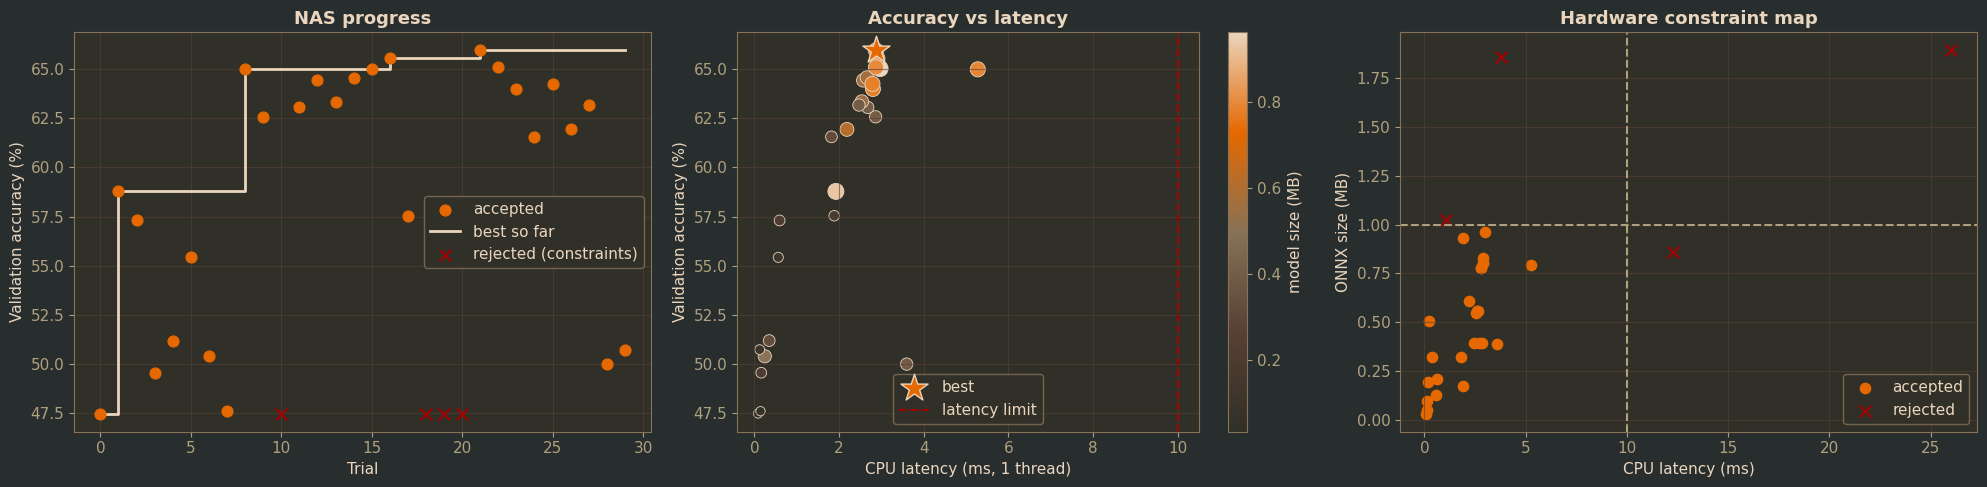

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# (a) search progress
ax[0].scatter(acc_df["trial"], acc_df["val_acc"] * 100, color=C["orange"], s=60, label="accepted", zorder=3)
ax[0].step(acc_df["trial"], acc_df["val_acc"].cummax() * 100, where="post", color=C["cream"], lw=2, label="best so far")
if len(rej_df):
    ymin = acc_df["val_acc"].min() * 100
    ax[0].scatter(rej_df["trial"], [ymin] * len(rej_df), color=C["red"], marker="x", s=70, label="rejected (constraints)", zorder=3)
ax[0].set_xlabel("Trial"); ax[0].set_ylabel("Validation accuracy (%)"); ax[0].set_title("NAS progress"); ax[0].legend()

# (b) latency vs accuracy
sc = ax[1].scatter(acc_df["latency_ms"], acc_df["val_acc"] * 100, c=acc_df["size_mb"], cmap=CMAP,
                   s=40 + acc_df["params"] / 2500, edgecolor=C["cream"], linewidth=0.6)
ax[1].scatter(best_row["latency_ms"], best_row["val_acc"] * 100, marker="*", s=420, color=C["orange"], edgecolor=C["cream"], zorder=5, label="best")
ax[1].axvline(CONSTRAINTS["max_latency_ms"], color=C["red"], ls="--", label="latency limit")
cb = plt.colorbar(sc, ax=ax[1]); cb.set_label("model size (MB)", color=C["cream"]); cb.ax.yaxis.set_tick_params(color=C["sand"])
plt.setp(cb.ax.get_yticklabels(), color=C["sand"])
ax[1].set_xlabel("CPU latency (ms, 1 thread)"); ax[1].set_ylabel("Validation accuracy (%)"); ax[1].set_title("Accuracy vs latency"); ax[1].legend()

# (c) feasibility map
ax[2].scatter(acc_df["latency_ms"], acc_df["size_mb"], color=C["orange"], s=55, label="accepted")
if len(rej_df):
    ax[2].scatter(rej_df["latency_ms"], rej_df["size_mb"], color=C["red"], marker="x", s=70, label="rejected")
ax[2].axvline(CONSTRAINTS["max_latency_ms"], color=C["sand"], ls="--"); ax[2].axhline(CONSTRAINTS["max_size_mb"], color=C["sand"], ls="--")
ax[2].set_xlabel("CPU latency (ms)"); ax[2].set_ylabel("ONNX size (MB)"); ax[2].set_title("Hardware constraint map"); ax[2].legend()
show("07_nas_search_results")

### 6.5 Train the best architecture from scratch  *(Deliverable 8)*
The search only used a short, small-data training. Now the winning architecture is trained **from scratch on the full CIFAR-10 training set** for longer and evaluated on the untouched test set.

[nas_best] epoch  1/30  loss 1.851  acc 45.81%  (7s)


[nas_best] epoch  2/30  loss 1.320  acc 58.21%  (7s)


[nas_best] epoch  3/30  loss 1.065  acc 63.25%  (7s)


[nas_best] epoch  4/30  loss 0.920  acc 69.31%  (7s)


[nas_best] epoch  5/30  loss 0.796  acc 74.18%  (7s)


[nas_best] epoch  6/30  loss 0.704  acc 77.48%  (7s)


... (21 outputs left out)

[nas_best] epoch 28/30  loss 0.185  acc 88.49%  (7s)


[nas_best] epoch 29/30  loss 0.181  acc 88.32%  (7s)


[nas_best] epoch 30/30  loss 0.178  acc 88.37%  (7s)



Best NAS architecture trained from scratch | params 199,362 | CIFAR-10 test accuracy 88.37%


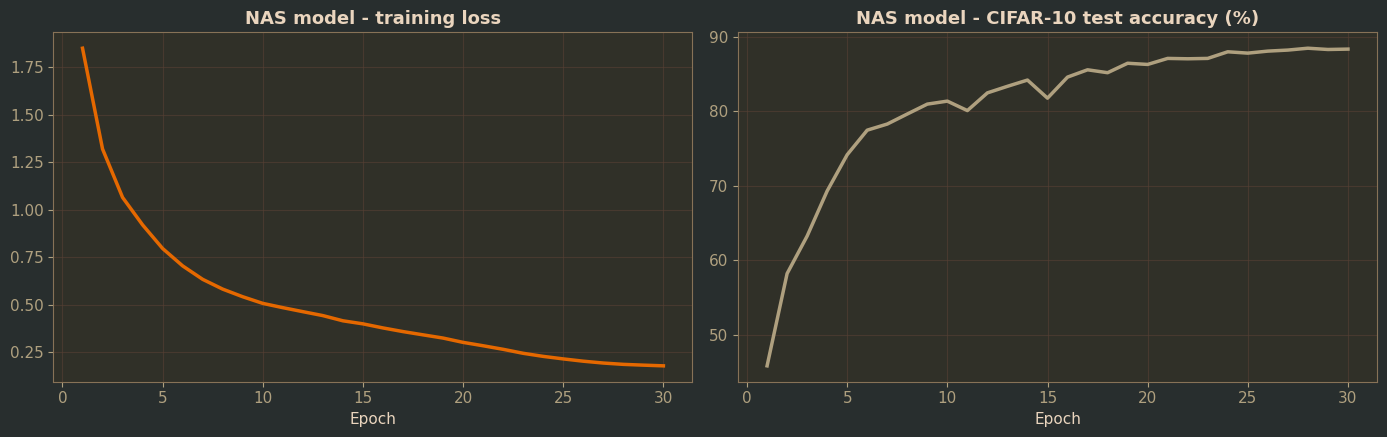

In [23]:
set_seed(SEED)
nas_model = build_model(best_cfg, 10)
if (CKPT / "nas_best.pt").exists() and not FORCE_RETRAIN:
    nas_model.load_state_dict(torch.load(CKPT / "nas_best.pt", map_location="cpu"))
    nas_model.to(DEVICE).eval()
    if "nas_best" not in HIST:
        a = evaluate(nas_model, D10["xte"], D10["yte"], D10["mean"], D10["std"], best_cfg["resolution"])
        HIST["nas_best"] = dict(epoch=[FINAL_NAS_EPOCHS], train_loss=[float("nan")], val_acc=[a], time=[0.0]); save_hist()
    print("[nas_best] loaded existing checkpoint - NOT retrained")
else:
    HIST["nas_best"] = train_model(nas_model, "nas_best", D10, FINAL_NAS_EPOCHS, lr=3e-3, res=best_cfg["resolution"],
                                   save_path=CKPT / "nas_best.pt")
    save_hist()
    # Keep nas_best_resume.pt for reproducibility and safe continuation.
nas_acc = evaluate(nas_model, D10["xte"], D10["yte"], D10["mean"], D10["std"], best_cfg["resolution"])
print(f"\nBest NAS architecture trained from scratch | params {count_params(nas_model):,} | CIFAR-10 test accuracy {nas_acc*100:.2f}%")

h = HIST["nas_best"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(h["epoch"], h["train_loss"], color=C["orange"], lw=2.5); ax[0].set_title("NAS model - training loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(h["epoch"], [a * 100 for a in h["val_acc"]], color=C["sand"], lw=2.5); ax[1].set_title("NAS model - CIFAR-10 test accuracy (%)"); ax[1].set_xlabel("Epoch")
show("08_nas_final_training")

### 6.6 Export the NAS model to ONNX and run it with the same unified pipeline

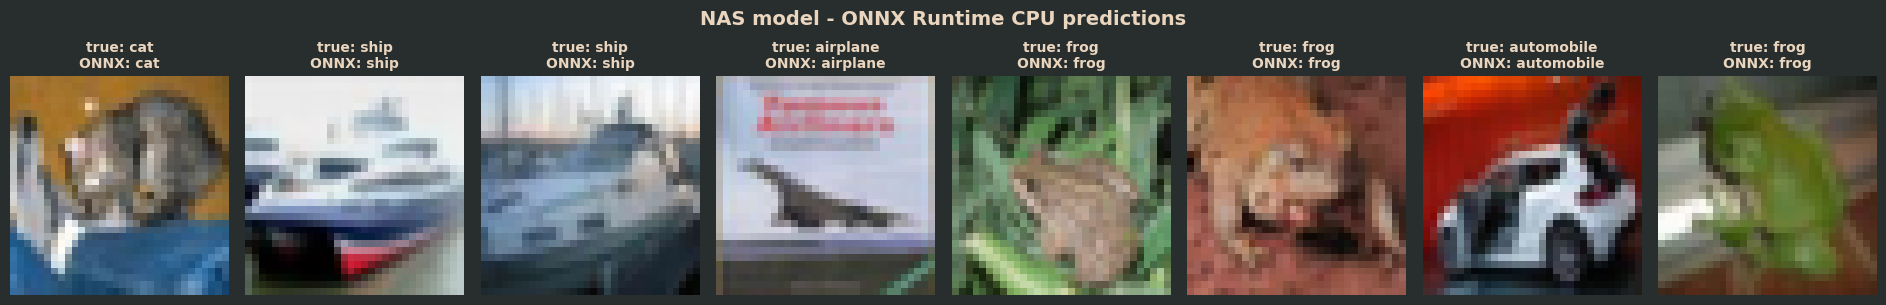

PyTorch and ONNX Runtime predict the same class on 8 / 8 images


In [24]:
REG["nas_best"] = dict(builder=lambda: build_model(best_cfg, 10), ckpt=CKPT / "nas_best.pt", onnx=ONNX_DIR / "nas_best.onnx",
                       data=D10, classes=D10["classes"], mean=D10["mean"].cpu(), std=D10["std"].cpu(), res=best_cfg["resolution"],
                       dataset="CIFAR-10", arch="NAS-best", variant="NAS")
export_onnx(nas_model, REG["nas_best"]["onnx"], best_cfg["resolution"])

xs10 = D10["xte"][:8].cpu(); ys10 = D10["yte"][:8].cpu().numpy()
pred_t = UnifiedPredictor("nas_best", "torch").predict(xs10)
pred_o = UnifiedPredictor("nas_best", "onnx").predict(xs10)
fig, axes = plt.subplots(1, 8, figsize=(19, 3.3))
for i, ax in enumerate(axes):
    ax.imshow(xs10[i].permute(1, 2, 0).numpy()); ax.axis("off")
    ok = pred_o[i][0][0] == D10["classes"][ys10[i]]
    ax.set_title(f"true: {D10['classes'][ys10[i]]}\nONNX: {pred_o[i][0][0]}", fontsize=10, color=C["cream"] if ok else C["orange"])
fig.suptitle("NAS model - ONNX Runtime CPU predictions", color=C["cream"], fontsize=14, fontweight="bold")
show("09_nas_onnx_predictions")
print("PyTorch and ONNX Runtime predict the same class on", sum(a[0][0] == b[0][0] for a, b in zip(pred_t, pred_o)), "/ 8 images")

## Part 7 - Benchmarking, README and packaging  *(Deliverables 11, 13)*
The benchmark runs every model (6 students + NAS model) and records: parameters, ONNX file size, accuracy (PyTorch on the full test set, ONNX Runtime on the first `ORT_EVAL_N` test images), agreement between PyTorch and ONNX, **median / p95 CPU latency** (1 thread, batch 1) and **peak inference memory**.

In [25]:
bench_rows = []
for key, info in REG.items():
    m = info["builder"](); m.load_state_dict(torch.load(info["ckpt"], map_location="cpu")); m.to(DEVICE).eval()
    d = info["data"]
    acc_torch = evaluate(m, d["xte"], d["yte"], d["mean"], d["std"], info["res"])
    n = min(ORT_EVAL_N, len(d["yte"]))
    xs_b, ys_b = d["xte"][:n].cpu(), d["yte"][:n].cpu().numpy()
    lg_t = UnifiedPredictor(key, "torch").logits(xs_b)
    lg_o = UnifiedPredictor(key, "onnx").logits(xs_b)
    sess = make_session(info["onnx"])
    lat, lat95 = measure_latency(sess, info["res"])
    bench_rows.append(dict(model=key, architecture=info["arch"], variant=info["variant"], dataset=info["dataset"],
                           params_M=count_params(m) / 1e6, onnx_size_MB=info["onnx"].stat().st_size / 1e6,
                           torch_test_acc=acc_torch * 100, onnx_acc=(lg_o.argmax(1) == ys_b).mean() * 100,
                           torch_onnx_agreement=(lg_t.argmax(1) == lg_o.argmax(1)).mean() * 100,
                           latency_ms_median=lat, latency_ms_p95=lat95, peak_mem_MB=measure_peak_mem(info["onnx"], info["res"])))
    pd.DataFrame(bench_rows).to_csv(RES_DIR / "benchmark_results.csv", index=False)
bench = pd.DataFrame(bench_rows)
bench.to_csv(RES_DIR / "benchmark_results.csv", index=False)
display(bench.round(3))

,model,architecture,variant,dataset,params_M,onnx_size_MB,torch_test_acc,onnx_acc,torch_onnx_agreement,latency_ms_median,latency_ms_p95,peak_mem_MB
0,mobilenet_v2_baseline,MobileNetV2,Baseline,CIFAR-100,2.352,9.381,56.04,56.80,100.0,2.426,2.753,30.156
1,mobilenet_v2_kd,MobileNetV2,Distilled,CIFAR-100,2.352,9.381,55.92,55.30,100.0,2.371,2.608,30.223
2,squeezenet_baseline,SqueezeNet,Baseline,CIFAR-100,0.774,3.111,53.33,53.55,100.0,6.158,6.473,14.074
3,squeezenet_kd,SqueezeNet,Distilled,CIFAR-100,0.774,3.111,50.80,51.95,100.0,6.155,6.529,14.609
4,efficientnet_lite0_baseline,EfficientNet-Lite0,Baseline,CIFAR-100,3.499,13.948,54.58,54.30,100.0,3.224,3.606,36.707
5,efficientnet_lite0_kd,EfficientNet-Lite0,Distilled,CIFAR-100,3.499,13.948,57.47,57.90,100.0,3.048,3.530,39.074
6,nas_best,NAS-best,NAS,CIFAR-10,0.199,0.802,88.37,88.35,100.0,2.862,3.175,10.395


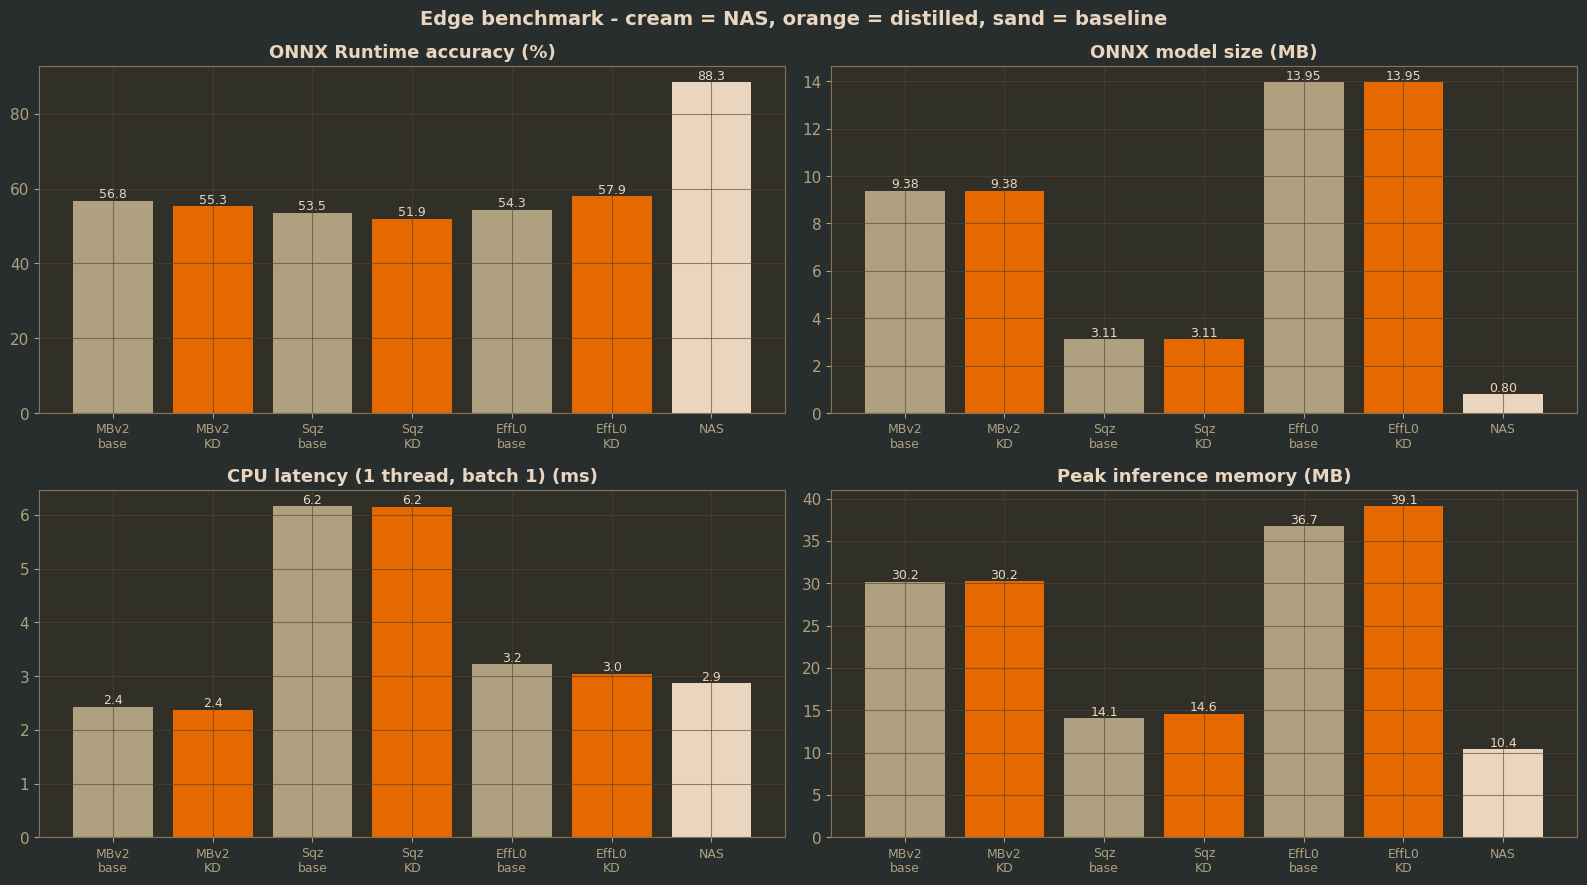

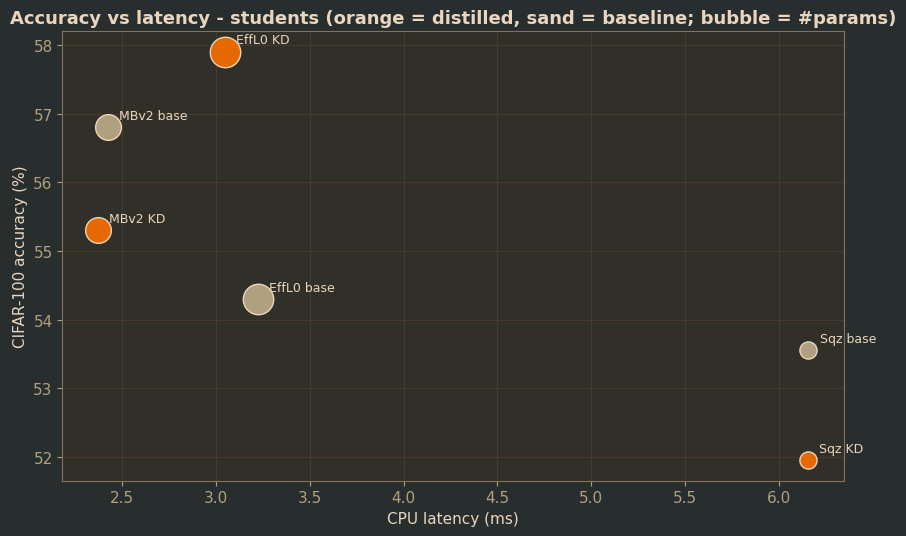

In [26]:
def label(r):
    base = {"MobileNetV2": "MBv2", "SqueezeNet": "Sqz", "EfficientNet-Lite0": "EffL0", "NAS-best": "NAS"}[r["architecture"]]
    return base if r["variant"] == "NAS" else f"{base}\n{'KD' if r['variant'] == 'Distilled' else 'base'}"
cols = [C["orange"] if v == "Distilled" else C["cream"] if v == "NAS" else C["sand"] for v in bench["variant"]]
labs = [label(r) for _, r in bench.iterrows()]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (col, ttl, unit) in zip(axes.flat, [("onnx_acc", "ONNX Runtime accuracy", "%"), ("onnx_size_MB", "ONNX model size", "MB"),
                                           ("latency_ms_median", "CPU latency (1 thread, batch 1)", "ms"), ("peak_mem_MB", "Peak inference memory", "MB")]):
    bars = ax.bar(labs, bench[col], color=cols)
    for b, v in zip(bars, bench[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.1f}" if col != "onnx_size_MB" else f"{v:.2f}",
                ha="center", va="bottom", fontsize=9, color=C["cream"])
    ax.set_title(f"{ttl} ({unit})"); ax.tick_params(axis="x", labelsize=9)
fig.suptitle("Edge benchmark - cream = NAS, orange = distilled, sand = baseline", color=C["cream"], fontsize=14, fontweight="bold")
show("10_benchmark_dashboard")

# accuracy vs latency trade-off (CIFAR-100 students)
fig, ax = plt.subplots(figsize=(9, 5.5))
b100 = bench[bench.dataset == "CIFAR-100"]
for _, r in b100.iterrows():
    ax.scatter(r["latency_ms_median"], r["onnx_acc"], s=60 + r["params_M"] * 120, edgecolor=C["cream"],
               color=C["orange"] if r["variant"] == "Distilled" else C["sand"], zorder=3)
    ax.annotate(label(r).replace("\n", " "), (r["latency_ms_median"], r["onnx_acc"]), textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xlabel("CPU latency (ms)"); ax.set_ylabel("CIFAR-100 accuracy (%)")
ax.set_title("Accuracy vs latency - students (orange = distilled, sand = baseline; bubble = #params)")
show("11_accuracy_vs_latency")

### 7.1 Standalone ONNX inference script, README, and ZIP package
This writes `onnx_infer.py` (a small script that only needs `onnxruntime`, `numpy`, `Pillow`) plus `meta.json`, a `README.md`, and zips the whole output folder for submission.

In [27]:
meta = {k: dict(onnx=v["onnx"].name, classes=v["classes"], mean=[float(a) for a in v["mean"]],
                std=[float(a) for a in v["std"]], res=int(v["res"])) for k, v in REG.items()}
json.dump(meta, open(ONNX_DIR / "meta.json", "w"))

INFER_SCRIPT = r"""
# Standalone CPU inference with ONNX Runtime.
# Usage: python onnx_infer.py --key mobilenet_v2_kd --image my_image.png --topk 5
import argparse, json, os
import numpy as np
import onnxruntime as ort
from PIL import Image

ap = argparse.ArgumentParser()
ap.add_argument("--key", required=True)
ap.add_argument("--image", required=True)
ap.add_argument("--topk", type=int, default=5)
ap.add_argument("--dir", default=os.path.dirname(os.path.abspath(__file__)))
a = ap.parse_args()

meta = json.load(open(os.path.join(a.dir, "meta.json")))[a.key]
res = meta["res"]
img = Image.open(a.image).convert("RGB").resize((res, res), Image.BILINEAR)
x = np.asarray(img, dtype=np.float32) / 255.0
x = (x - np.array(meta["mean"], dtype=np.float32)) / np.array(meta["std"], dtype=np.float32)
x = x.transpose(2, 0, 1)[None].astype(np.float32)

so = ort.SessionOptions(); so.intra_op_num_threads = 1
sess = ort.InferenceSession(os.path.join(a.dir, meta["onnx"]), so, providers=["CPUExecutionProvider"])
logits = sess.run(None, {sess.get_inputs()[0].name: x})[0][0]
p = np.exp(logits - logits.max()); p /= p.sum()
for j in np.argsort(-p)[:a.topk]:
    print(meta["classes"][j].ljust(20), "%6.2f%%" % (p[j] * 100))
"""
(ONNX_DIR / "onnx_infer.py").write_text(INFER_SCRIPT.strip() + "\n")

README = """
# Assignment 4 - Knowledge Distillation + Hardware-Aware NAS (Edge Computing & Intelligent Systems)

## Requirements
Python 3.10+, PyTorch, torchvision, timm, onnx, onnxruntime, optuna, pandas, matplotlib
(see requirements.txt)

## How to run
1. Run setup once (see README_LOCAL.md), start Jupyter, open the notebook.
2. Run all cells top to bottom. If it stops, run all cells again - finished work is reloaded. Use `QUICK_TEST = True` first for a ~10 min smoke test.
3. Outputs are written to `EdgeAI_Assignment4/`.

## Folder structure
- `checkpoints/` teacher (ResNet-50), 3 baseline students, 3 distilled students, best NAS model (`.pt`)
- `onnx/` ONNX models for all students and the NAS model, `meta.json`, `onnx_infer.py`
- `results/` `kd_vs_baseline.csv`, `nas_search_history.csv/json`, `best_architecture.json`, `benchmark_results.csv`, `histories.json`
- `figures/` all plots used in the report

## Run ONNX inference on CPU
    python onnx/onnx_infer.py --key mobilenet_v2_kd --image my_image.png
Keys: mobilenet_v2_baseline, mobilenet_v2_kd, squeezenet_baseline, squeezenet_kd,
efficientnet_lite0_baseline, efficientnet_lite0_kd, nas_best

## Notebook sections vs. assignment deliverables
| # | Deliverable | Notebook section |
|---|---|---|
| 1 | Teacher model | Part 1 |
| 2 | Student architectures | Part 2 |
| 3 | Baseline students | Part 3 |
| 4 | Knowledge distillation | Part 4 |
| 5 | NAS search space | Part 6.1 |
| 6 | NAS algorithm (Optuna TPE) | Part 6.2-6.3 |
| 7 | NAS results | Part 6.4 |
| 8 | Optimised architecture | Part 6.5 |
| 9 | Inference pipeline | Part 5.2, 7.1 |
| 10 | ONNX deployment | Part 5, 6.6, 7.1 |
| 11 | Benchmarking | Part 7 |
"""
(ROOT / "README.md").write_text(README.strip() + "\n")

zip_path = Path(str(ROOT) + ".zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in ROOT.rglob("*"):
        if f.is_file() and not f.name.endswith(("_resume.pt", ".tmp")) and (not f.name.endswith("_best.pt") or f.name == "nas_best.pt") and not f.name.startswith("nas_t") and "data" not in f.relative_to(ROOT).parts and "epochs" not in f.relative_to(ROOT).parts:
            z.write(f, f.relative_to(ROOT.parent))
print("Created:", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
for f in sorted(ROOT.rglob("*")):
    if f.is_file():
        print("  ", f.relative_to(ROOT))

Created: C:\Edge_assignment_4\EdgeAI_Local\EdgeAI_Local\EdgeAI_Assignment4.zip (189.6 MB)
   checkpoints\efficientnet_lite0_baseline.pt
   checkpoints\efficientnet_lite0_baseline_best.pt
   checkpoints\efficientnet_lite0_baseline_resume.pt
   checkpoints\efficientnet_lite0_kd.pt
   checkpoints\efficientnet_lite0_kd_best.pt
   checkpoints\efficientnet_lite0_kd_resume.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_001.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_002.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_003.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_004.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_005.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_006.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_007.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_008.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_009.pt
   checkpoints\epochs\efficientnet_lite0_baseline\epoch_010.p

## Completed experiment

All training, NAS, ONNX inference and benchmark outputs are saved in this notebook. Final checkpoints, CSV/JSON results, figures and `Technical_Report.pdf` are in `EdgeAI_Assignment4/` in the project (or the submission root after extracting the ZIP). Every completed epoch is retained locally in `checkpoints/epochs/`.

The final submission package is `23i-0061_AI-7B.zip`. Source and results repository: https://github.com/Fahid0088/Knowledge_Distilation_-_NAS
